# Análisis exploratorio de la OBT MC1

Esta libreta analiza `OBT_MC1_RN` antes de seleccionar características o
entrenar un clasificador de fallas en los próximos 30 días.

Las consultas sobre la población completa se ejecutan **en Snowflake**
mediante el conector Spark–Snowflake. El proceso local de Spark solo
recibe resultados pequeños y acotados para tablas y figuras. No se
descarga la OBT ni se usan transformaciones locales sobre sus filas.

Hay eventos de falla registrados tanto en 2018 como en 2019. Se analiza
su distribución por año; contar con eventos en ambos períodos no garantiza
por sí solo que el registro de fallas sea exhaustivo.


Este archivo fue generado durante el desarrollo del PSET 2 copiado aqui para cumplir con los requisitos de analisis
del laboratorio de la semana 08

## 0. Conexión, alcance y límites de ejecución


In [1]:
"""
Configuración inicial del análisis exploratorio de la OBT MC1.

Esta celda prepara las dependencias, establece la conexión con Spark
y Snowflake, define el contrato de la tabla de origen y configura
los límites de ejecución del análisis exploratorio.

IMPORTANTE:
    - Las consultas sobre la población completa se ejecutan en Snowflake.
    - Spark recibe únicamente los resultados de las consultas.
    - Los límites configurados restringen la cantidad de filas devueltas,
      no la cantidad de registros procesados por Snowflake.
    - Los análisis adicionales permanecen desactivados por defecto
      para controlar el consumo de créditos del warehouse.
"""


# ============================================================
# 1. IMPORTACIONES Y DEPENDENCIAS
# ============================================================

"""
Dependencias necesarias para el análisis.

os:
    Acceso a las variables de entorno del contenedor.

re:
    Validación de identificadores utilizados en consultas SQL.

sys y Path:
    Utilidades del entorno Python y manejo de rutas.

matplotlib.pyplot:
    Generación de gráficos estadísticos.

pandas:
    Manipulación de resultados agregados de pequeño tamaño.

pyspark:
    Acceso al entorno Spark y consulta de su versión.

snowflake_io:
    Funciones compartidas para establecer una sesión Spark
    y ejecutar consultas SQL mediante el conector Snowflake.
"""

import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyspark

from snowflake_io import create_spark_session, read_snowflake_query


spark = create_spark_session("mc1-obt-eda")
"""Sesión Spark utilizada para ejecutar las consultas de la EDA."""

OBT_SCHEMA = "S_CDATOS_PSET2_OBT"
"""Esquema de Snowflake que contiene las tablas de la capa OBT."""

OBT_NAME = "OBT_MC1_RN"
DATABASE = os.environ["SNOWFLAKE_DATABASE"].strip()

IDENTIFIER = re.compile(r"^[A-Za-z_][A-Za-z0-9_$]*$")

if not IDENTIFIER.fullmatch(DATABASE):
    raise ValueError(
        "Nombre de base de datos no admitido por esta libreta"
    )

OBT_TABLE = f'"{DATABASE}"."{OBT_SCHEMA}"."{OBT_NAME}"'


COLUMNS_TABLE = f'"{DATABASE}".INFORMATION_SCHEMA.COLUMNS'



"""Identificadores de los 22 atributos SMART retenidos para MC1."""
SMART_IDS = (
    1, 5, 9, 12,
    170, 171, 172, 173, 174, 180,
    183, 184, 187, 188,
    194, 195, 196, 197, 198, 199,
    206, 211,
)

"""
Duración de las ventanas temporales, expresadas en días calendario.

7 días: Describe el comportamiento más reciente del SSD.
14 días: Permite observar variaciones de mediano plazo.
30 días: Resume el comportamiento durante un período más amplio.
"""

WINDOWS = (7, 14, 30)

"""
Columnas utilizadas para identificar una observación.

SMART_DAILY_KEY: Identificador técnico único de cada observación.
SSD_KEY: Identificador de la unidad SSD.
DISK_ID: Identificador original de la unidad.
MODEL_CODE: Modelo del dispositivo. Debe ser MC1.
OBSERVATION_DATE_KEY: lave de la dimensión de fechas.
OBSERVATION_DATE: Fecha calendario de la observación.
"""
IDENTITY_COLUMNS = (
    "SMART_DAILY_KEY",
    "SSD_KEY",
    "DISK_ID",
    "MODEL_CODE",
    "OBSERVATION_DATE_KEY",
    "OBSERVATION_DATE",
)


LABEL_COLUMNS = (
    "FIRST_FAILURE_DATE",
    "LAST_SEEN_DATE",
    "DAYS_TO_FAILURE",
    "LABEL_STATUS",
    "TARGET_30D",
)
"""
Columnas relacionadas con el etiquetado de fallas.

FIRST_FAILURE_DATE: rimera fecha de falla registrada para el SSD.

LAST_SEEN_DATE: Última fecha de telemetría disponible para el SSD.

DAYS_TO_FAILURE: Diferencia en días entre la observación y la primera falla.

LABEL_STATUS:
    Estado de la observación:
        POSITIVE: existe un registro de una falla dentro de la ventana de 30 dias desde la fecha de medicion.
        Esta ventana representa especificamente el primer evento de fallo desde la fecha de medicion, por lo
        que la existencia de la clase POST-FAILURE es importante.
        NEGATIVE: En este caso si no hay un evento de falla en los proximos 30 dias desde la observacion actual,
        el sistema lo marca como un negativo.
        CENSORED: en este caso, no tenemos la suficiente informacion luego de una serie de observaciones para
        marcar la lectura como negativa o positiva. Durante nuestro analisis con GPT, notamos que podia haber
        SSDs que despues de una fecha determinada, desaparezcan del dataset. Alibaba documenta que puede
        haber SSDs que desaparezcan porque sus duenos optaron por que no sean recolectadas en este dataset,
        pero tambien pueden haber casos de manteinimiento y reemplazo programado y una SSD puede desaparecer
        del dataset. En el caso de no tener una medicion dentro del rango de 30 dias desde una observacion, la
        implementacion lo marca como censored porque no podemos tener la data suficiente para esos dias.
        SAME_DAY_FAILURE: esta es la flag que se aplica a un registro de una SSD si este registro tiene su
        fecha de observacion == a la fecha de falla. Como no podemos saber si el error sucedio antes de un
        replay de los registros SMART por ejemplo, o despues, asignamos esta flag
        POST_FAILURE: representa los registros, posteriores a la primera fecha de falla, registrada de la
        misma SSD en el dataset. Estos eventos no son errores, pero son parte de otra parte que no aplica
        para el proyecto. En nuestro planteamiento, queremos entrenar un modelo capaz de predecir si una
        SSD tendra un fallo dentro de los siguientes 30 dias, no necesariamente si luego de este fallo
        lograra recuperarse, usamos estos 30 dias como la base para el entrenamiento. Como un sistema puede
        liberar mediciones de estadisticas luego de que la SSD se recupere de un error transitorio, o
        despues que una SSD tenga un reboot, etc., esta SSD puede presentar mas mediciones, pero no
        usamos esta informacion porque nuestro objetivo es aislar a los errores dentro de la ventana futura de
        30 dias
`
TARGET_30D: Variable objetivo de clasificación.

    1: falla registrada en los siguientes 30 días.
    0: ausencia de falla registrada dentro del horizonte,
       según las reglas de etiquetado y seguimiento.
    NULL: observación excluida de la población supervisada.

"""


MAX_METADATA_ROWS = 1200
MAX_SUMMARY_ROWS = 60
MAX_PLOT_ROWS = 2000

# ===================


# ============================================================
# 10. ANÁLISIS DE RELACIONES ENTRE VARIABLES SMART
# ============================================================

"""
Configuración de la comparación entre dos características SMART.

Este análisis es independiente de la comparación principal
entre una característica y TARGET_30D.

Permite estudiar la asociación entre dos mediciones mediante:
    - Conteo de pares utilizables.
    - Covarianza.
    - Correlación.
    - Diagrama de dispersión acotado.

No se realiza una matriz completa de correlaciones.
"""

RUN_PAIR_ANALYSIS = False
"""
Habilita la comparación exploratoria entre dos campos SMART.

False:
    Omite la comparación.

True:
    Permite seleccionar dos campos distintos y ejecutar
    sus consultas y visualizaciones.

La correlación resultante no demuestra causalidad ni
capacidad predictiva por sí sola.
"""


# ============================================================
# 11. ANÁLISIS DE TRAYECTORIAS PREVIAS A LA FALLA
# ============================================================

"""
Configuración de las visualizaciones temporales.

Estas visualizaciones permiten observar cómo evolucionan
las mediciones SMART conforme se aproxima una falla.

Se distinguen dos análisis:
    - Trayectoria de una unidad SSD específica.
    - Trayectoria agregada de múltiples SSD con fallas.

Ambos son exploratorios y permanecen desactivados
durante la ejecución económica por defecto.
"""

RUN_TRAJECTORY = False
"""
Activa la trayectoria temporal de un SSD específico.

Cuando se habilita:
    - Selecciona determinísticamente un SSD con falla.
    - Recupera una cantidad acotada de observaciones.
    - Representa la evolución de características SMART.
    - Señala la fecha de la primera falla.

El caso individual es ilustrativo y no demuestra
que el mismo patrón ocurra en otros SSD.
"""

RUN_AGGREGATE_TRAJECTORY = False
"""
Activa el análisis temporal agregado previo a la falla.

Agrupa observaciones positivas mediante DAYS_TO_FAILURE
y calcula estadísticas descriptivas para cada día
del horizonte predictivo.

Permite explorar si existe una tendencia común a medida
que se aproxima la falla.

Los SSD que contribuyen a cada día pueden ser diferentes,
por lo que la evolución agregada no debe interpretarse
automáticamente como deterioro individual.
"""



print("Versión de PySpark:", pyspark.__version__)
print("Tabla de origen:", OBT_TABLE)
print(
    "Almacén configurado:",
    os.environ.get("SNOWFLAKE_WAREHOUSE", "[sin definir]")
)
print(
    "La sesión Spark es local; "
    "las consultas de la OBT se envían a Snowflake."
)

26/10/21 01:48:24 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/21 01:48:24 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/10/21 01:48:24 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.


Versión de PySpark: 4.0.4
Tabla de origen: "S_CDATOS_PSET2"."S_CDATOS_PSET2_OBT"."OBT_MC1_RN"
Almacén configurado: COMPUTE_WH
La sesión Spark es local; las consultas de la OBT se envían a Snowflake.


In [50]:
"""
Activa el análisis en profundidad de las características R_5.

False: Se respetan las selecciones individuales de RUN_R5_FEATURES.
True: Se habilita el conjunto completo de características R_5 contempladas en el análisis en profundidad.
"""
RUN_IN_DEPTH_ANALYSIS = False

"""
Controla la ejecución de los análisis de valores extremos.

False: Omite las consultas adicionales basadas en el IQR
True: Permite ejecutar análisis IQR de las características
    cuyos bloques estén habilitados.
"""
RUN_IQR_ANALYSIS = True


#! Controlada por la variable RUN_IN_DEPTH_ANALYSIS. Si se habilita, se ejecutan todos los bloques de R_5.
RUN_R5_FEATURES = {
    "R_5": True,                 # Valor raw diario.

    "R_5_MEAN_7D": False,        # Media de los últimos 7 días.
    "R_5_MEAN_14D": False,       # Media de los últimos 14 días.
    "R_5_MEAN_30D": False,       # Media de los últimos 30 días.

    "R_5_MEAN_SHIFT_7D": False,  # Cambio entre medias de 7 días.
    "R_5_MEAN_SHIFT_14D": False, # Cambio entre medias de 14 días.
    "R_5_MEAN_SHIFT_30D": False, # Cambio entre medias de 30 días.
}


"""
Habilita el análisis de una familia SMART elegida mediante el menú.

False: No ejecuta los bloques de la familia alternativa.

True: Permite elegir una familia SMART y ejecutar sus campos según RUN_SELECTED_FAMILY_FIELDS.

"""
RUN_SELECTED_FAMILY = False

#! Controlador por RUN_SELECTED_FAMILY. Si se habilita, se ejecutan los bloques de la familia elegida según RUN_SELECTED_FAMILY_FIELDS.
RUN_SELECTED_FAMILY_FIELDS = {
    "": True,                    # Valor diario de la familia.

    "_MEAN_7D": False,           # Media de 7 días.
    "_MEAN_14D": False,          # Media de 14 días.
    "_MEAN_30D": False,          # Media de 30 días.

    "_MEAN_SHIFT_7D": False,     # Cambio de medias de 7 días.
    "_MEAN_SHIFT_14D": False,    # Cambio de medias de 14 días.
    "_MEAN_SHIFT_30D": False,    # Cambio de medias de 30 días.
}

### 0.1 Contrato para recibir solo resultados pequeños

`query_small` añade un límite exterior de seguridad y rechaza cualquier
resultado que exceda el máximo declarado. Cada consulta de detalle
incluye además su propio orden estable y límite. El límite **no**
sustituye la agregación: todas las operaciones sobre millones de filas
deben estar dentro del SQL enviado a Snowflake.


In [3]:
def query_small(sql: str, *, max_rows: int = MAX_SUMMARY_ROWS) -> pd.DataFrame:
    if max_rows < 1 or max_rows > MAX_PLOT_ROWS:
        raise ValueError("Límite de resultados fuera del rango permitido")
    statement = sql.strip().rstrip(";")
    if not statement.upper().startswith(("SELECT", "WITH")) or ";" in statement:
        raise ValueError("Solo se admiten consultas SELECT de una sentencia")
    guarded = f"SELECT * FROM ({statement}) AS RESULTADO LIMIT {max_rows + 1}"
    result = read_snowflake_query(spark, guarded, schema=OBT_SCHEMA).toPandas()
    if len(result) > max_rows:
        raise RuntimeError(
            f"Resultado demasiado grande: más de {max_rows} filas. "
            "Agregue o reduzca los datos en Snowflake."
        )
    return result


def quote_feature(column: str) -> str:
    if column not in FEATURE_NAMES:
        raise ValueError("La característica no pertenece al registro MC1")
    return '"' + column + '"'


def show_table(frame: pd.DataFrame, *, empty_message: str) -> None:
    if frame.empty:
        print(empty_message)
    else:
        display(frame)


def assert_zero_counts(frame: pd.DataFrame, *names: str) -> None:
    """Bloquea resultados si una validación indica fallos o devuelve NULL."""
    if len(frame) != 1:
        raise AssertionError(f"La validación esperaba una fila; recibió {len(frame)}")
    violations = {}
    for name in names:
        value = frame.iloc[0][name]
        if pd.isna(value):
            violations[name] = "NULL (recuento ambiguo)"
        elif int(value) != 0:
            violations[name] = int(value)
    if violations:
        raise AssertionError(f"Validaciones incumplidas: {violations}")
    print("Validaciones correctas:", ", ".join(names))


### 0.2 Confirmación del almacén de cómputo de Snowflake


In [4]:
runtime = query_small("""
    SELECT CURRENT_DATABASE() AS BASE_DE_DATOS,
           CURRENT_WAREHOUSE() AS ALMACEN_DE_COMPUTO,
           CURRENT_ROLE() AS ROL,
           CURRENT_TIMESTAMP() AS FECHA_DE_EJECUCION
""", max_rows=1)
display(runtime)
print("Compruebe en Query History que las consultas extensas usen este almacén.")


26/10/21 01:48:39 WARN NoOpFileCacheManager: Cache is not available. Caching will be disabled. Set the HOME, SF_TEMPORARY_CREDENTIAL_CACHE_DIR, or net.snowflake.jdbc.temporaryCredentialCacheDir to enable caching.
26/10/21 01:48:40 ERROR RestRequest: Stop retrying since elapsed time due to network issues has reached timeout. Elapsed: 1,044 ms, timeout: 1,000 ms
26/10/21 01:48:40 ERROR RestRequest: Stop retrying since elapsed time due to network issues has reached timeout. Elapsed: 1,045 ms, timeout: 1,000 ms
26/10/21 01:48:40 ERROR RestRequest: Returning null response. Cause: java.net.UnknownHostException: metadata.google.internal, request: GET http://metadata.google.internal HTTP/1.1
26/10/21 01:48:40 ERROR RestRequest: Returning null response. Cause: java.net.UnknownHostException: metadata.google.internal, request: GET http://metadata.google.internal/computeMetadata/v1/instance/service-accounts/default/email HTTP/1.1
26/10/21 01:48:40 ERROR RestRequest: Stop retrying since elapsed tim

,BASE_DE_DATOS,ALMACEN_DE_COMPUTO,ROL,FECHA_DE_EJECUCION
0,S_CDATOS_PSET2,COMPUTE_WH,ACCOUNTADMIN,2026-10-21 01:48:46.173


Compruebe en Query History que las consultas extensas usen este almacén.


## 1. Salud estructural de la OBT


### 1.1 Inventario de columnas y tipos

El contrato esperado tiene 847 columnas: seis de identidad, cinco de
etiqueta y 836 características SMART (`22 × 2 × 19`). La consulta a
`INFORMATION_SCHEMA` lee metadatos, no filas de telemetría.


In [8]:
column_inventory = query_small(f"""
    SELECT COLUMN_NAME, DATA_TYPE, NUMERIC_PRECISION, NUMERIC_SCALE,
           CHARACTER_MAXIMUM_LENGTH, ORDINAL_POSITION
    FROM {COLUMNS_TABLE}
    WHERE TABLE_SCHEMA = '{OBT_SCHEMA}' AND TABLE_NAME = '{OBT_NAME}'
    ORDER BY ORDINAL_POSITION
""", max_rows=MAX_METADATA_ROWS)

def expected_schema() -> dict[str, str]:
    expected = {
        "SMART_DAILY_KEY": "VARCHAR(128)",
        "SSD_KEY": "VARCHAR(128)",
        "DISK_ID": "NUMBER(38,0)",
        "MODEL_CODE": "VARCHAR(50331648)",
        "OBSERVATION_DATE_KEY": "NUMBER(8,0)",
        "OBSERVATION_DATE": "DATE",
        "FIRST_FAILURE_DATE": "DATE",
        "LAST_SEEN_DATE": "DATE",
        "DAYS_TO_FAILURE": "NUMBER(38,0)",
        "LABEL_STATUS": "VARCHAR(134217728)",
        "TARGET_30D": "NUMBER(38,0)",
    }
    for prefix in ("R", "N"):
        for smart_id in SMART_IDS:
            root = f"{prefix}_{smart_id}"
            expected[root] = "NUMBER(38,6)"
            for window in WINDOWS:
                suffix = f"{window}D"
                expected[f"{root}_MEAN_{suffix}"] = "NUMBER(38,10)"
                expected[f"{root}_COUNT_{suffix}"] = "NUMBER(38,0)"
                expected[f"{root}_PREV_COUNT_{suffix}"] = "NUMBER(38,0)"
                expected[f"{root}_MEAN_VALID_{suffix}"] = "NUMBER(38,0)"
                expected[f"{root}_MEAN_SHIFT_{suffix}"] = "NUMBER(38,9)"
                expected[f"{root}_MEAN_SHIFT_VALID_{suffix}"] = "NUMBER(38,0)"
    return expected


def observed_type(row) -> str:
    kind = str(row.DATA_TYPE).upper()
    if kind in {"TEXT", "VARCHAR"}:
        return f"VARCHAR({int(row.CHARACTER_MAXIMUM_LENGTH)})"
    if kind in {"NUMBER", "DECIMAL", "NUMERIC"}:
        return f"NUMBER({int(row.NUMERIC_PRECISION)},{int(row.NUMERIC_SCALE)})"
    return kind


EXPECTED_SCHEMA = expected_schema()
observed = {row.COLUMN_NAME: observed_type(row) for row in column_inventory.itertuples()}
missing = sorted(set(EXPECTED_SCHEMA) - set(observed))
unexpected = sorted(set(observed) - set(EXPECTED_SCHEMA))
mistyped = [
    (name, EXPECTED_SCHEMA[name], observed[name])
    for name in sorted(set(EXPECTED_SCHEMA) & set(observed))
    if EXPECTED_SCHEMA[name] != observed[name]
]
schema_summary = pd.DataFrame([{
    "COLUMNAS_ESPERADAS": len(EXPECTED_SCHEMA),
    "COLUMNAS_OBSERVADAS": len(column_inventory),
    "COLUMNAS_FALTANTES": len(missing),
    "COLUMNAS_INESPERADAS": len(unexpected),
    "TIPOS_DIFERENTES": len(mistyped),
    "COLUMNAS_R": sum(name.startswith("R_") for name in observed),
    "COLUMNAS_N": sum(name.startswith("N_") for name in observed),
}])

if missing or unexpected or mistyped:
    display(pd.DataFrame(mistyped, columns=["COLUMNA", "TIPO_ESPERADO", "TIPO_OBSERVADO"]))
    print("Faltantes:", missing)
    print("Inesperadas:", unexpected)
    raise RuntimeError("El esquema vivo no coincide con el contrato de la OBT MC1")
FEATURE_NAMES = set(observed) - set(IDENTITY_COLUMNS) - set(LABEL_COLUMNS)
print("El esquema coincide con las 847 columnas esperadas.")


El esquema coincide con las 847 columnas esperadas.


In [9]:
schema_summary

,COLUMNAS_ESPERADAS,COLUMNAS_OBSERVADAS,COLUMNAS_FALTANTES,COLUMNAS_INESPERADAS,TIPOS_DIFERENTES,COLUMNAS_R,COLUMNAS_N
0,847,847,0,0,0,418,418


En este caso, la cantidad de columnas es conocida, pero lo mas importante es que la validación de los tipos de datos
desde la data at rest en Snowflake corresponde al esquema reportado y a los tipos de datos esperados.

### 1.2 Población, fechas y modelo


In [10]:
population = query_small(f"""
    SELECT COUNT(*) AS OBSERVACIONES,
           COUNT(DISTINCT SSD_KEY) AS SSD_DISTINTOS,
           MIN(OBSERVATION_DATE) AS FECHA_MINIMA,
           MAX(OBSERVATION_DATE) AS FECHA_MAXIMA,
           COALESCE(COUNT_IF(MODEL_CODE IS NULL OR MODEL_CODE <> 'MC1'), 0)
               AS MODELOS_INESPERADOS,
           COALESCE(COUNT_IF(OBSERVATION_DATE < DATE '2018-01-01'
                    OR OBSERVATION_DATE > DATE '2019-12-31'), 0)
               AS FECHAS_FUERA_DE_RANGO,
           COALESCE(COUNT_IF(SMART_DAILY_KEY IS NULL OR SSD_KEY IS NULL
                    OR OBSERVATION_DATE IS NULL), 0) AS CLAVES_INCOMPLETAS
    FROM {OBT_TABLE}
""", max_rows=1)
print("Referencia Gold histórica: 115 159 020 observaciones y 199 655 SSD.")


Referencia Gold histórica: 115 159 020 observaciones y 199 655 SSD.
La comparación es informativa; no sustituye el recuento de la OBT actual.


In [104]:
population

,OBSERVACIONES,SSD_DISTINTOS,FECHA_MINIMA,FECHA_MAXIMA,MODELOS_INESPERADOS,FECHAS_FUERA_DE_RANGO,CLAVES_INCOMPLETAS
0,115159020,199655,2018-01-03,2019-12-31,0,0,0


Esta es la base del sistema. La aplicación espera tener datos desde el 2018 hasta el 2019, esto se refleja en los
registros de la base mostrando registros reales desde el 2018 enero 3 hasta el 2019 diciembre 31, lo que coincide con
 el planteamiento inicial desarrollado para la presentación y propuesta del modelo, y todavía presenta los datos
 necesarios como para realizar los *splits* temporales planteados. En este caso, las siguientes columnas representan
 detalles adicionales importantes:

- La ausencia de modelos inesperados es una validación real, dado que el modelo se plantea para que aprenda solamente
 de la familia de SSDs MC1 que presenta la mayor cantidad de fallas y por tanto la mayor cantidad de registros
 utilizables para el entrenamiento. Si teníamos algún modelo fuera de lugar, esto indicaría una mala construcción de
 la OBT final
 - La ausencia de fechas fuera de lugar también es importante, dado que el dataset y nuestro entendimiento de este
 comprende solamente la data entre el 2018 y el 2019.
  - Finalmente, la falta de claves incompletas demuestra que no hay nulos en las llaves tomadas desde el lado del
  esquema de constelación creado en la capa Gold. Dado que en esta capa se asocia una sola SSD_KEY con una sola
  combinacion de DISC_ID y MODEL_ID y una sola SMART_DAILY_KEY comformada por el HASH de la clave SSD_KEY asociada
  con el dispositivo en el registro SMART, y la OBSERVATION_KEY asociada con la fecha del registro SMART, notamos que
   la asuencia de claves imcompletas demuestra que cada observacion mantiene una asociaci[on con su disco original y
   con la fecha de registro.

### 1.3 Unicidad de la clave técnica


In [12]:
technical_duplicates = query_small(f"""
    WITH repeated AS (
        SELECT SMART_DAILY_KEY, COUNT(*) AS ROWS_PER_KEY
        FROM {OBT_TABLE}
        GROUP BY SMART_DAILY_KEY
        HAVING COUNT(*) > 1
    )
    SELECT COUNT(*) AS CLAVES_REPETIDAS,
           COALESCE(SUM(ROWS_PER_KEY - 1), 0) AS FILAS_EXCEDENTES
    FROM repeated
""", max_rows=1)



In [101]:
technical_duplicates

,CLAVES_REPETIDAS,FILAS_EXCEDENTES
0,0,0


El resultado anterior se justifica además con los registros de la tabla de auditoría creada en base al proceso
OBT ejecutado anteriormente para la creación de la tabla de datos, en donde el resultado demuestra:

| RUN_ID                                                           | POPULATION_CODE | STARTED_AT_UTC                | COMPLETED_AT_UTC              | RUN_STATUS | GOLD_OBSERVATION_COUNT | GOLD_SSD_COUNT | MC1_OBT_ROW_COUNT | MC1_OBT_DISTINCT_SSD_COUNT | POSITIVE_COUNT | NEGATIVE_COUNT | CENSORED_COUNT | SAME_DAY_FAILURE_COUNT | POST_FAILURE_COUNT | DUPLICATE_SMART_DAILY_KEY_COUNT | R_N_COUNT_MISMATCH_COUNT | INVALID_ROLLING_COUNT_COUNT | INVALID_MEAN_COUNT | INVALID_SHIFT_COUNT | MULTIPLE_FAILURE_SSD_COUNT | ERROR_MESSAGE                                                                                |
| ---------------------------------------------------------------- | --------------- | ----------------------------- | ----------------------------- | ---------- | ---------------------- | -------------- | ----------------- | -------------------------- | -------------- | -------------- | -------------- | ---------------------- | ------------------ | ------------------------------- | ------------------------ | --------------------------- | ------------------ | ------------------- | -------------------------- | -------------------------------------------------------------------------------------------- |
| a62bfc4fbc79c60ef9a29686eb515248fb2d63e748a400d8e553fb9fec77e3b7 | MC1             | 2026-10-01 15:15:34.445 -0700 | 2026-10-01 15:20:21.068 -0700 | SUCCEEDED  | 2645                   | 100            | 2645              | 100                        | 0              | 2623           | 22             | 0                      | 0                  | 0                               | 0                        | 0                           | 0                  | 0                   | 0                          | NON_PRODUCTION: canonical publication skipped; validated run-scoped staging tables retained. |
| 7c0bd45f96de1db23a5934cb3b484127f0daf10ad7b9b96316052850c604e5f2 | MC1             | 2026-10-01 15:26:51.172 -0700 | 2026-10-01 16:16:36.254 -0700 | SUCCEEDED  | 115159020              | 199655         | 115159020         | 199655                     | 291528         | 109800252      | 4564943        | 2714                   | 499583             | 0                               | 0                        | 0                           | 0                  | 0                   | 0<br>                      |                                                                                              |

En este caso, sabemos que la tabla final no contiene registros duplicados tanto en SSDs como en fechas, lo que indica
 que los resultados son confiables, en términos de duplicados para trabajar en un entrenamiento

### 1.4 Unicidad de SSD y fecha


In [14]:
daily_duplicates = query_small(f"""
    WITH repeated AS (
        SELECT SSD_KEY, OBSERVATION_DATE, COUNT(*) AS ROWS_PER_DAY
        FROM {OBT_TABLE}
        GROUP BY SSD_KEY, OBSERVATION_DATE
        HAVING COUNT(*) > 1
    )
    SELECT COUNT(*) AS PARES_REPETIDOS,
           COALESCE(SUM(ROWS_PER_DAY - 1), 0) AS FILAS_EXCEDENTES
    FROM repeated
""", max_rows=1)



In [102]:
daily_duplicates

,PARES_REPETIDOS,FILAS_EXCEDENTES
0,0,0


El resultado anterior comprueba las validaciones iniciales y el diseno realizado para implementar la OBT, no existe
lecturas repetidas dentro de la data si manejamos el dataset MC1 dado que, por lo general, el dataset registra una
lectura por SSD por dia, por lo que al filtrar a MC1 mantenemos la misma estructura.

Notamos que si existieran duplicados en los registros notariamos que existiririan hashes similares y por tanto
duplicados en las claves primarias de la tabla. Hay una validacion durante la construccion de la OBT que revisa por
esto, pero es importante notar que la validacion funciona y los resultados mantienen la relacion unica entre una
observacion y la SSD registrada.

### 1.5 Muestras acotadas de duplicados, solo si existen


In [16]:
if int(technical_duplicates.iloc[0]["CLAVES_REPETIDAS"]) > 0:
    display(query_small(f"""
        SELECT SMART_DAILY_KEY, COUNT(*) AS REPETICIONES
        FROM {OBT_TABLE}
        GROUP BY SMART_DAILY_KEY HAVING COUNT(*) > 1
        ORDER BY REPETICIONES DESC, SMART_DAILY_KEY LIMIT 20
    """, max_rows=20))
if int(daily_duplicates.iloc[0]["PARES_REPETIDOS"]) > 0:
    display(query_small(f"""
        SELECT SSD_KEY, OBSERVATION_DATE, COUNT(*) AS REPETICIONES
        FROM {OBT_TABLE}
        GROUP BY SSD_KEY, OBSERVATION_DATE HAVING COUNT(*) > 1
        ORDER BY REPETICIONES DESC, SSD_KEY, OBSERVATION_DATE LIMIT 20
    """, max_rows=20))
if not int(technical_duplicates.iloc[0]["CLAVES_REPETIDAS"]) and not int(daily_duplicates.iloc[0]["PARES_REPETIDOS"]):
    print("No se encontraron claves diarias duplicadas.")


No se encontraron claves diarias duplicadas.


### 1.6 Compuerta de validación estructural


In [17]:
if population.empty or int(population.iloc[0]["OBSERVACIONES"]) <= 0:
    raise AssertionError("La OBT no tiene observaciones para analizar")
assert_zero_counts(
    population, "MODELOS_INESPERADOS", "FECHAS_FUERA_DE_RANGO", "CLAVES_INCOMPLETAS"
)
assert_zero_counts(technical_duplicates, "CLAVES_REPETIDAS", "FILAS_EXCEDENTES")
assert_zero_counts(daily_duplicates, "PARES_REPETIDOS", "FILAS_EXCEDENTES")
print("Integridad estructural validada; se permite continuar con las etiquetas.")


Validaciones correctas: MODELOS_INESPERADOS, FECHAS_FUERA_DE_RANGO, CLAVES_INCOMPLETAS
Validaciones correctas: CLAVES_REPETIDAS, FILAS_EXCEDENTES
Validaciones correctas: PARES_REPETIDOS, FILAS_EXCEDENTES
Integridad estructural validada; se permite continuar con las etiquetas.


## 2. Distribución y consistencia de la variable objetivo

Uno de los principales problemas posibles en el caso de los datos corresponde a la existencia de un imbalance,
que se pudo notar hasta en la tabla anterior de auditoría, en donde hay muchos más registros censurados (en
donde no se vio al dispositivo dentro del periodo de 30 días siguientes ni tampoco luego=, o casos negativos
en donde no hay un registro de daño en el periodo de 30 días siguientes, que positivos, en donde sí hay un
registro de daño en el periodo de 30 días siguientes. Para trabajar con el modelo entonces vamos a necesitar
realizar un proceso de resampling, hasta undersampling the las clases negativas y asuentes para poder eliminar
el riesgo de que el modelo aprenda solamente las características de las clases mayoritarias.


### 2.1 Estados de etiqueta y SSD distintos


In [18]:
label_distribution = query_small(f"""
    WITH grouped AS (
        SELECT LABEL_STATUS,
               COUNT(*) AS OBSERVACIONES,
               COUNT(DISTINCT SSD_KEY) AS SSD_DISTINTOS
        FROM {OBT_TABLE}
        GROUP BY LABEL_STATUS
    )
    SELECT LABEL_STATUS, OBSERVACIONES, SSD_DISTINTOS,
           ROUND(100.0 * OBSERVACIONES / NULLIF(SUM(OBSERVACIONES) OVER (), 0), 6)
               AS PORCENTAJE_OBSERVACIONES
    FROM grouped
    ORDER BY OBSERVACIONES DESC, LABEL_STATUS
""", max_rows=20)




,LABEL_STATUS,OBSERVACIONES,SSD_DISTINTOS,PORCENTAJE_OBSERVACIONES
0,NEGATIVE,109800252,198121,95.346636
1,POSITIVE,291528,10379,0.253153
2,CENSORED,4564943,190672,3.964034
3,SAME_DAY_FAILURE,2714,2714,0.002357
4,POST_FAILURE,499583,3153,0.433820


In [103]:
label_distribution

,LABEL_STATUS,OBSERVACIONES,SSD_DISTINTOS,PORCENTAJE_OBSERVACIONES
0,NEGATIVE,109800252,198121,95.346636
1,POSITIVE,291528,10379,0.253153
2,CENSORED,4564943,190672,3.964034
3,SAME_DAY_FAILURE,2714,2714,0.002357
4,POST_FAILURE,499583,3153,0.433820


In [19]:
allowed_statuses = {
    "POSITIVE", "NEGATIVE", "CENSORED", "SAME_DAY_FAILURE", "POST_FAILURE"
}
found_statuses = set(label_distribution["LABEL_STATUS"].dropna().tolist())
if label_distribution.empty or label_distribution["LABEL_STATUS"].isna().any() or not found_statuses <= allowed_statuses:
    raise AssertionError(
        f"Estados de etiqueta no válidos: {found_statuses - allowed_statuses}"
    )

En este caso, debemos de separar las diferentes nociones anteriores sobre el tamano de los grupos, los reportes
actuales de las marcas positivas, las SSD distintas etc.

1. En primer lugar, dentro del dataset existen 10510 eventos reales, encontrados mediante el analisis de las
etiquetas de fallos en su propio EDA realizado durante el pset2, que corresponden a la clase MC1 siendo esta la mas
grande en el sistema.
2. En segundo lugar, dentro del dataset general existen 199 655 SSDs distintas, es decir diferentes modelos de SSDs.
Este detalle se presenta anteriormente pero es importante destacarlo. El mecanismo de calculo de estas evalua las
SSD_Keys como criterio de distincion y unicidad. Como las SSD keys fueron creadas de tal manera que cada una
represente una sola SSD basada en la clave interna de (DISK_ID, MODEL_CODE/ID), podemos entender que la cantidad de
SSD_KEY(s) debe ser la misma cantidad de SSDs distintas y por tanto sabemos que existen 199 655 modelos distintos
debido a la construccion de la tabla de modelos y la validacion realizada. Esto significa que para el caso de MC1,
existen 199 655 SSDs cuyo modelo es MC1 y que tienen diferentes variaciones de DISK_IDs.
3. En tercer, lugar, un valor importante mostrando en la tabla anterior corresponde a la cantidad de SSDs distntas
que presenta una label positiva. Como sabemos, una label positiva corresponde a la etiqueta asignada a toda aquella
lectura SMART que tiene un registro de falla dentro de los 30 días siguientes a la fecha de observación, donde si hay
 una lectura en el mismo dia usamos la etiqueta SAME_DAY_FAILURE y si hay una lectura posterior a la fecha de falla
 usamos la etiqueta POST_FAILURE. En este caso, la cantidad de SSDs distintas que presentan una etiqueta positiva es
 de 10 379 correspondientes a 131 SSDs menos que la cantidad de eventos de falla reales registrados en el dataset. La
  cantidad de 10 379 SSDs distintos corresponde a todas aquellas SSD_Keys que registraron una falla dentro de los 30
  días siguientes a la fecha de observación. Las 131 que quedaron fuera corresponden a aquellas que no aportan una
  sola instancia de una label positiva. Esto puede ser porque las fallas no tienen ninguna medicion en un intervalo
  de 30 dias para la correspondiente SSD_KEY, o porque la falla esta en una posicion temporal en donde el corte de
  los datos no permite la existencia de datos, etc.
4. Ademas es importante notar el valor de 2174, correspondiente a que existen 2174 registros de telemetria SMART
asociados con el mismo dia de la falla para 2174  SSDS unicas. Esto es interesante porque demuestra que no todas las
SSDs realmente se mantienen vivas hasta el momento de su falla para el sistema que recolecto las metricas. Para estas
 2174 es posible que el sistema haya marcado una falla y la SSD no haya tenido una falla que acabe con su
 funcionalidad totalmente, pero que haya tenido un error grave que cause que se registre como una falla, pero que
 posteriormente el sistema haya podido recuperar la funcionalidad de la SSD y por tanto haya podido seguir
 recolectando las metricas. Esta medicion de 2174 demuestra que los datos no solamente tienen un corte antes de la
 fecha de la falla, sno que es posiubl, debido al tipo de falla no conocido, que el proceso de recoleccion se haya
 ejecutado igualmente.
5. Finalmente, es de suma importancia destacar la discrepancia encontrada entre la cantidad de SSDs unicas en el caso
 de labels positivas y labels de post failure. Es importante notar que los grupos de analisis representados no son
 exactamente parejos ni se solapan completamente, por ejemplo, es posible que una SSD no tenga registros antes de la
 fecha de falla registrada, pero luego registre una medicion todos los dias. En este caso, todas estas se marcan como
  POST_FAILURE porque la primera falla ya se registro y por tanto no genera casos de tipo POSITIVE. Asimismo, es
  posible que una lectura que genere casos POSITIVE, por estar detras de una fecha de falla, genere estas lecturas
  pero luego de la falla nunca mas vuelva a registrar telemetria SMART. En este caso no aumentara la cantidad de SSDs
   distintas en el grupo de POST_FAILURE. Por tanto, la diferencia fundamental radica en que los grupos de POSITIVE y
    POST_FAILURE no son exactamente los mismos, y por tanto la cantidad de SSDs depende del tipo de falla (una
    variable aleatoria externa al dataset) y de la cantidad de registros SMART que se registren antes y despues de la falla

Estas distinciones son importantes para definir las cantidades con las que se puede operar en el dataset, que no
corresponde a los 115 millones de filas, ni tampoco a todos los 450 000 registros censurados, etc.

#### 2.1.1 Evaluacion del Sopalamiento entre las clases posibles de la label

In [105]:
ssd_failure_overlap = query_small(f"""
    WITH per_ssd AS (
        SELECT
            SSD_KEY,
            MAX(IFF(LABEL_STATUS = 'POSITIVE', 1, 0)) AS HAS_POSITIVE,
            MAX(IFF(LABEL_STATUS = 'SAME_DAY_FAILURE', 1, 0)) AS HAS_SAME_DAY,
            MAX(IFF(LABEL_STATUS = 'POST_FAILURE', 1, 0)) AS HAS_POST_FAILURE
        FROM {OBT_TABLE}
        GROUP BY SSD_KEY
    )
    SELECT
        COUNT_IF(HAS_POSITIVE = 1) AS SSDS_POSITIVE,
        COUNT_IF(HAS_SAME_DAY = 1) AS SSDS_SAME_DAY,
        COUNT_IF(HAS_POST_FAILURE = 1) AS SSDS_POST_FAILURE,
        COUNT_IF(HAS_POSITIVE = 1 AND HAS_POST_FAILURE = 1)
            AS SSDS_BOTH,
        COUNT_IF(HAS_POSITIVE = 1 AND HAS_POST_FAILURE = 0)
            AS SSDS_POSITIVE_ONLY,
        COUNT_IF(HAS_POSITIVE = 0 AND HAS_POST_FAILURE = 1)
            AS SSDS_POST_FAILURE_ONLY
    FROM per_ssd
""", max_rows=MAX_SUMMARY_ROWS)

,SSDS_POSITIVE,SSDS_SAME_DAY,SSDS_POST_FAILURE,SSDS_BOTH,SSDS_POSITIVE_ONLY,SSDS_POST_FAILURE_ONLY
0,10379,2714,3153,3115,7264,38


In [106]:
ssd_failure_overlap

,SSDS_POSITIVE,SSDS_SAME_DAY,SSDS_POST_FAILURE,SSDS_BOTH,SSDS_POSITIVE_ONLY,SSDS_POST_FAILURE_ONLY
0,10379,2714,3153,3115,7264,38


#### 2.1.2 Visualizacion final de la composicion de las salidas positivas, post failure y same day y su solapamiento

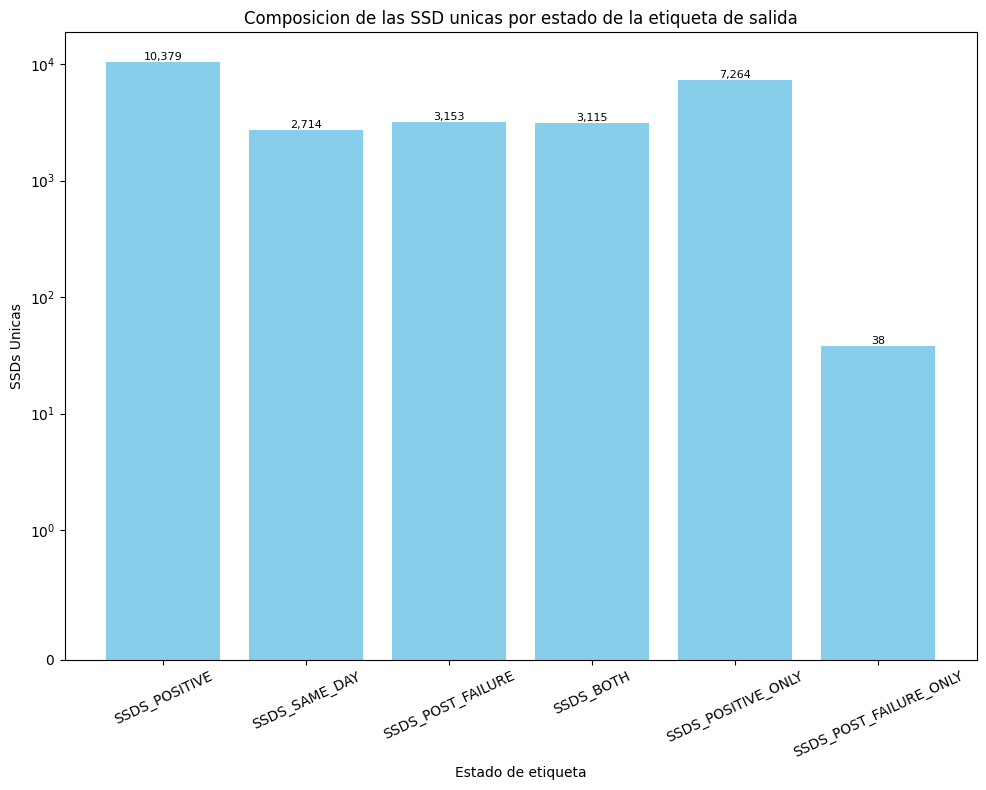

In [110]:
if not ssd_failure_overlap.empty:
    temp = ssd_failure_overlap.transpose().rename(columns={0: "SSD UNICAS"})
    figure, axis = plt.subplots(figsize=(10, 8))
    axis.bar(temp.index, temp["SSD UNICAS"], color="skyblue")
    axis.set_title("Composicion de las SSD unicas por estado de la etiqueta de salida")
    axis.set_xlabel("Estado de etiqueta")
    axis.set_ylabel("SSDs Unicas")
    axis.set_yscale("symlog", linthresh=1)
    for bar in axis.patches:
        axis.annotate(f"{int(bar.get_height()):,}",
                      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                      ha="center", va="bottom", fontsize=8, rotation=0)
    axis.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()


En base a la evaluacion anterior, notamos que existe un solapamiento entre las clases POSITIVE y POST FAILURE para
3115 diferentes SSD_KEYS o 3115 diferentes SSDs registradas. El registro demuestra que existen 7264 SSDs distintas
que tienen solamente registros positivos y ningun tipo de registro de POST_FAILURE, y 38 cuyo registro es solamente
tiene POST FAILURE labels y nada de postiive tags.

Esto significa que para 38 SSD_KEYS en el sistema, estos no registras mediciones SMART antes de la primera fecha de
falla registrada en el sistema, y por tanto no tienen registros de POSITIVE, pero si tienen registros de POST_FAILURE
. Por otro lado, existen 3115 SSDS que presentan el caso ideal en donde tienen tanto registros positivos y mantienene
 registros posteriores.

### 2.2 Figura 1: composición de las etiquetas


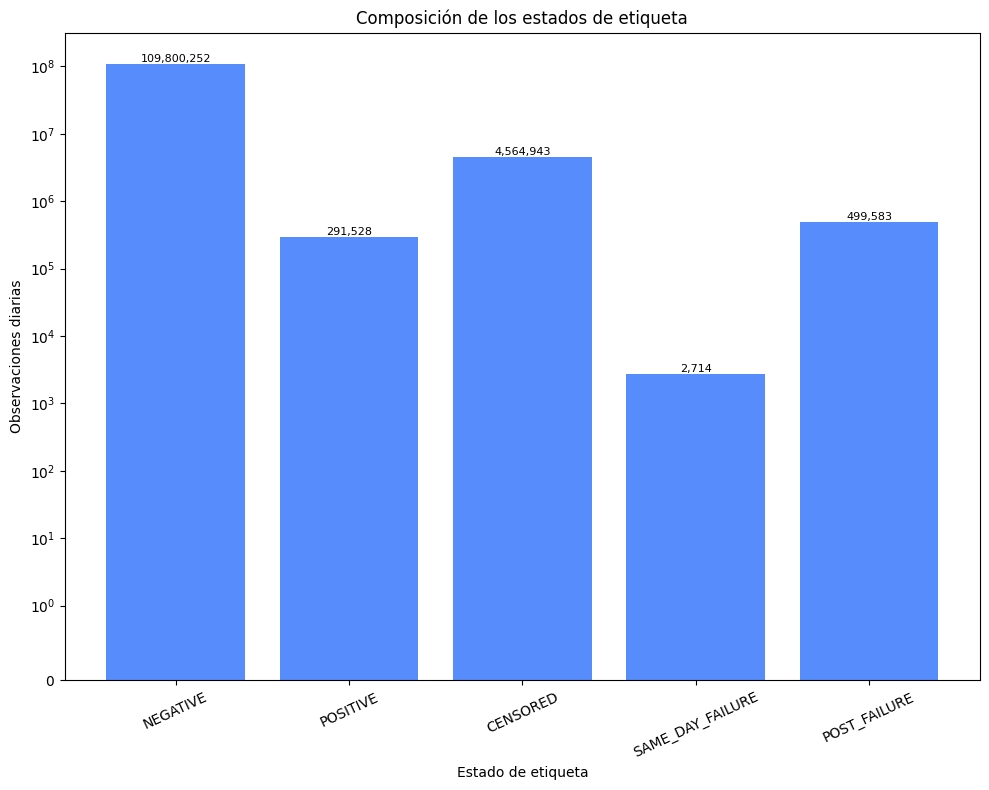

In [28]:
if not label_distribution.empty:
    figure, axis = plt.subplots(figsize=(10, 8))
    axis.bar(label_distribution["LABEL_STATUS"].fillna("SIN_ESTADO"),
             label_distribution["OBSERVACIONES"].astype(float))
    axis.set_title("Composición de los estados de etiqueta")
    axis.set_xlabel("Estado de etiqueta")
    axis.set_ylabel("Observaciones diarias")
    axis.set_yscale("symlog", linthresh=1)
    for bar in axis.patches:
        axis.annotate(f"{int(bar.get_height()):,}",
                      (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                      ha="center", va="bottom", fontsize=8, rotation=0)
    axis.tick_params(axis="x", rotation=25)
    plt.tight_layout()
    plt.show()


In [21]:
training_population = query_small(f"""
    SELECT COALESCE(COUNT_IF(LABEL_STATUS = 'POSITIVE'), 0) AS POSITIVAS,
           COALESCE(COUNT_IF(LABEL_STATUS = 'NEGATIVE'), 0) AS NEGATIVAS,
           COALESCE(COUNT_IF(LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')), 0) AS ELEGIBLES,
           COUNT(DISTINCT IFF(LABEL_STATUS = 'POSITIVE', SSD_KEY, NULL))
               AS SSD_CON_POSITIVOS,
           COUNT(DISTINCT IFF(FIRST_FAILURE_DATE IS NOT NULL, SSD_KEY, NULL))
               AS SSD_CON_PRIMERA_FALLA_REGISTRADA,
           ROUND(
               COALESCE(COUNT_IF(LABEL_STATUS = 'POSITIVE'), 0) /
               NULLIF(COALESCE(COUNT_IF(LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')), 0), 0), 8
           ) AS TASA_POSITIVA,
           ROUND(
               COALESCE(COUNT_IF(LABEL_STATUS = 'NEGATIVE'), 0) /
               NULLIF(COALESCE(COUNT_IF(LABEL_STATUS = 'POSITIVE'), 0), 0), 4
           ) AS RAZON_NEGATIVAS_POR_POSITIVA
    FROM {OBT_TABLE}
""", max_rows=1)
print("La tasa usa observaciones, no eventos independientes de falla.")


,POSITIVAS,NEGATIVAS,ELEGIBLES,SSD_CON_POSITIVOS,SSD_CON_PRIMERA_FALLA_REGISTRADA,TASA_POSITIVA,RAZON_NEGATIVAS_POR_POSITIVA
0,291528,109800252,110091780,10379,10508,0.002648,376.6371


La tasa usa observaciones, no eventos independientes de falla.


In [111]:
training_population

,POSITIVAS,NEGATIVAS,ELEGIBLES,SSD_CON_POSITIVOS,SSD_CON_PRIMERA_FALLA_REGISTRADA,TASA_POSITIVA,RAZON_NEGATIVAS_POR_POSITIVA
0,291528,109800252,110091780,10379,10508,0.002648,376.6371


Aqui es importante notar que el algoritmo usado para contar los registros demuestra que tenemos 291 528 registros
positivos en el dataset mientras que tenemos 109 800 252 registros negativos, dandonos una razon diminuta con
respeccto de los positivos contra los labels negativos en el dataset. Teniendo esto en cuenta es claro que una
tecnica de **resampling** y **undersampling** de las clases tendra que ser usada para la correcta extraccion de los
registros de entrenamiento.

Adicionalmente, el resultado permite distinguir entre la cantidad de unidades SSD con una primera falla registrada y
aquellas que aportan observaciones positivas para el entrenamiento. En la tabla Gold de eventos de falla se identificaron **10 510 eventos correspondientes a unidades SSD del modelo MC1**. Sin embargo, de estas unidades, solamente **10.508 cuentan con registros de telemetría SMART** y, por lo tanto, pueden encontrarse en la OBT.

Esta cantidad se obtiene mediante el conteo de valores distintos de `SSD_KEY` para los cuales `FIRST_FAILURE_DATE` no es nulo. Dado que la OBT se construye a partir de las observaciones SMART, el conteo considera únicamente unidades SSD presentes en dicha tabla, independientemente de que sus observaciones estén clasificadas como positivas, negativas, censuradas, correspondientes al día de falla o posteriores a esta.

Los dos eventos restantes, ambos registrados el **4 de enero de 2018**, corresponden a unidades SSD sin observaciones asociadas en `FCT_SMART_DAILY_MC1`, según la verificación realizada sobre la capa Gold. Por esta razón, no están representados en la OBT.

Por otra parte, de las 10.508 unidades con falla registrada y telemetría disponible, solamente **10.379 presentan al menos una observación positiva** dentro de los 30 días anteriores a su primera falla. Esto deja 129 unidades con una falla conocida, pero sin observaciones que cumplan la condición necesaria para recibir la etiqueta `POSITIVE`.

#### 2.3.1 Evaluacion de los eventos

In [115]:
failures_with_no_telemetry_attached = query_small(f"""
    SELECT
        f.SSD_KEY,
        f.FAILURE_DATE,
        f.FAILURE_EVENT_KEY
    FROM S_CDATOS_PSET2.S_CDATOS_PSET2_GOLD.FCT_FAILURE_EVENT_MC1 f
    WHERE NOT EXISTS (
        SELECT 1
        FROM S_CDATOS_PSET2.S_CDATOS_PSET2_GOLD.FCT_SMART_DAILY_MC1 s
        WHERE s.SSD_KEY = f.SSD_KEY
        );
""", max_rows=MAX_SUMMARY_ROWS);

Py4JJavaError: An error occurred while calling o362.collectToPython.
: net.snowflake.client.api.exception.SnowflakeSQLException: Your account is suspended due to lack of payment method.
	at net.snowflake.client.internal.jdbc.SnowflakeUtil.checkErrorAndThrowExceptionSub(SnowflakeUtil.java:180)
	at net.snowflake.client.internal.jdbc.SnowflakeUtil.checkErrorAndThrowException(SnowflakeUtil.java:112)
	at net.snowflake.client.internal.core.StmtUtil.pollForOutput(StmtUtil.java:513)
	at net.snowflake.client.internal.core.StmtUtil.execute(StmtUtil.java:418)
	at net.snowflake.client.internal.core.SFStatement.executeHelper(SFStatement.java:505)
	at net.snowflake.client.internal.core.SFStatement.executeQueryInternal(SFStatement.java:214)
	at net.snowflake.client.internal.core.SFStatement.executeQuery(SFStatement.java:148)
	at net.snowflake.client.internal.core.SFStatement.execute(SFStatement.java:777)
	at net.snowflake.client.internal.core.SFStatement.execute(SFStatement.java:695)
	at net.snowflak

### 2.4 Estados de etiqueta por año


In [23]:
labels_by_year = query_small(f"""
    SELECT YEAR(OBSERVATION_DATE) AS ANIO, LABEL_STATUS,
           COUNT(*) AS OBSERVACIONES,
           COUNT(DISTINCT SSD_KEY) AS SSD_DISTINTOS
    FROM {OBT_TABLE}
    GROUP BY YEAR(OBSERVATION_DATE), LABEL_STATUS
    ORDER BY ANIO, LABEL_STATUS
""", max_rows=50)


In [24]:
labels_by_year

,ANIO,LABEL_STATUS,OBSERVACIONES,SSD_DISTINTOS
0,2019,CENSORED,4500245,187951
1,2019,NEGATIVE,56358279,193650
2,2019,POSITIVE,234886,8427
3,2018,POSITIVE,56642,2148
4,2019,POST_FAILURE,389481,2581
5,2019,SAME_DAY_FAILURE,1446,1446
6,2018,NEGATIVE,53441973,188848
7,2018,CENSORED,64698,2818
8,2018,POST_FAILURE,110102,1382
9,2018,SAME_DAY_FAILURE,1268,1268


En este caso, la tabla anterior demuestra que existen **10 575** SSDs distintos que reistran eventos positivos.
Anteriormente notamos que existian **10 379** SSDs con registros positivos, la diferencia claramente radica en que la
 anterior consulta buscaba las SSDs unicas que presentaban al menos un registro SMART que haya causado una label
 positiva, mientras que en este analisis, la evaluacion se hace por cada anio, resultando en un conteo repedito que
 demuestra que existen SSDs que se encuentran tanto en 2018 y 2019

### 2.5 Figura 2: distribución anual de las etiquetas


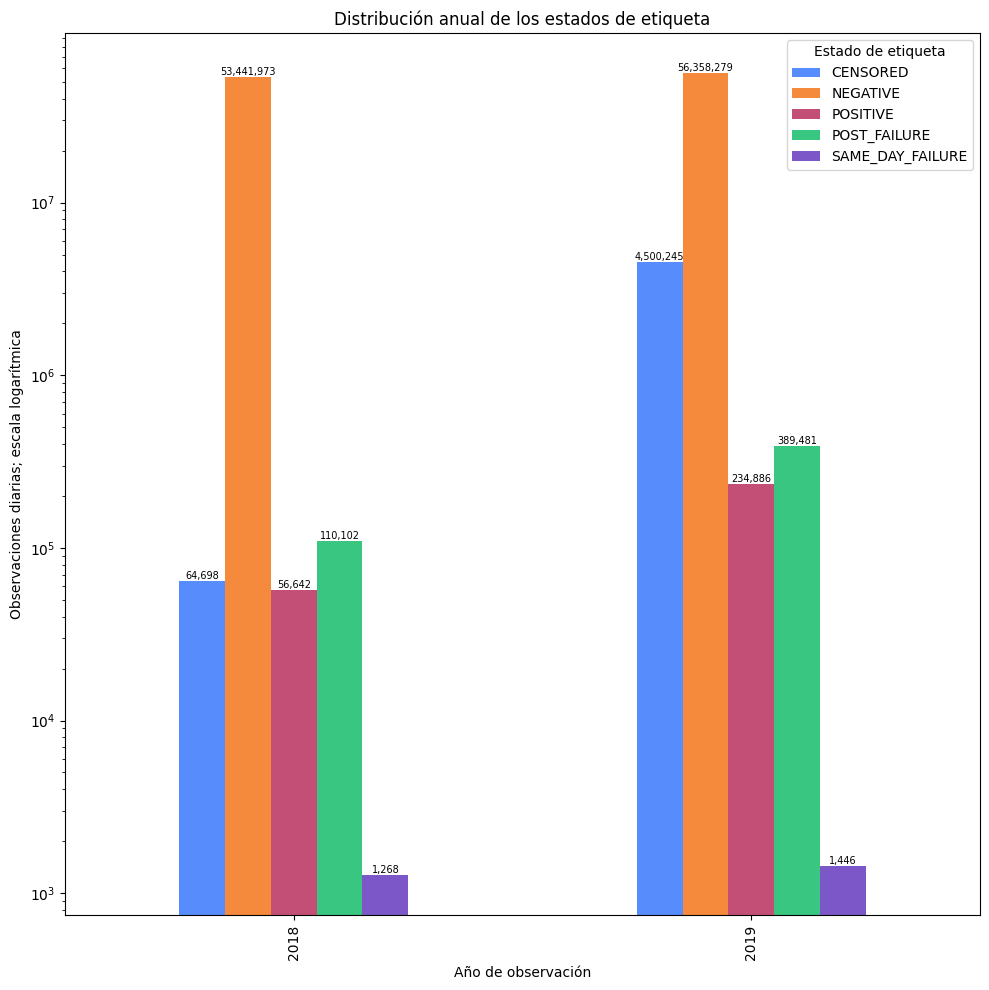

In [27]:
if not labels_by_year.empty:
    chart_rows = labels_by_year.copy()
    chart_rows["OBSERVACIONES"] = pd.to_numeric(chart_rows["OBSERVACIONES"])
    plot_data = chart_rows.pivot_table(
        index="ANIO", columns="LABEL_STATUS", values="OBSERVACIONES", fill_value=0
    )
    axis = plot_data.plot(kind="bar", figsize=(10, 10), logy=True)
    axis.set_title("Distribución anual de los estados de etiqueta")
    axis.set_xlabel("Año de observación")
    axis.set_ylabel("Observaciones diarias; escala logarítmica")
    axis.legend(title="Estado de etiqueta")
    for bar in axis.patches:
        if bar.get_height() > 0:
            axis.annotate(f"{int(bar.get_height()):,}",
                          (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                          ha="center", va="bottom", fontsize=7, rotation=0)
    plt.tight_layout()
    plt.show()


### 2.6 Verificación de las reglas de etiquetado

Se recomputan el estado, el objetivo y la distancia a la primera falla
con la prioridad usada para construir la OBT. Esta verificación comprueba
la coherencia interna, **no** la completitud externa del archivo de
fallas. No se transfieren filas individuales.


In [29]:
label_consistency = query_small(f"""
    WITH expected AS (
        SELECT LABEL_STATUS, TARGET_30D, DAYS_TO_FAILURE,
               DATEDIFF('day', OBSERVATION_DATE, FIRST_FAILURE_DATE)
                   AS EXPECTED_DAYS,
               CASE
                   WHEN FIRST_FAILURE_DATE IS NOT NULL
                        AND OBSERVATION_DATE > FIRST_FAILURE_DATE
                       THEN 'POST_FAILURE'
                   WHEN FIRST_FAILURE_DATE IS NOT NULL
                        AND OBSERVATION_DATE = FIRST_FAILURE_DATE
                       THEN 'SAME_DAY_FAILURE'
                   WHEN DATEDIFF('day', OBSERVATION_DATE, FIRST_FAILURE_DATE)
                        BETWEEN 1 AND 30 THEN 'POSITIVE'
                   WHEN LAST_SEEN_DATE >= DATEADD('day', 30, OBSERVATION_DATE)
                       THEN 'NEGATIVE'
                   ELSE 'CENSORED'
               END AS EXPECTED_STATUS
        FROM {OBT_TABLE}
    )
    SELECT COALESCE(COUNT_IF(LABEL_STATUS IS DISTINCT FROM EXPECTED_STATUS), 0)
               AS ESTADOS_INCONSISTENTES,
           COALESCE(COUNT_IF(TARGET_30D IS DISTINCT FROM
               CASE EXPECTED_STATUS WHEN 'POSITIVE' THEN 1
                    WHEN 'NEGATIVE' THEN 0 ELSE NULL END), 0)
               AS OBJETIVOS_INCONSISTENTES,
           COALESCE(COUNT_IF(DAYS_TO_FAILURE IS DISTINCT FROM EXPECTED_DAYS), 0)
               AS DISTANCIAS_INCONSISTENTES
    FROM expected
""", max_rows=1)

assert_zero_counts(
    label_consistency,
    "ESTADOS_INCONSISTENTES", "OBJETIVOS_INCONSISTENTES", "DISTANCIAS_INCONSISTENTES"
)


Validaciones correctas: ESTADOS_INCONSISTENTES, OBJETIVOS_INCONSISTENTES, DISTANCIAS_INCONSISTENTES


In [30]:
label_consistency

,ESTADOS_INCONSISTENTES,OBJETIVOS_INCONSISTENTES,DISTANCIAS_INCONSISTENTES
0,0,0,0


**Interpretación de la sección 2.** Distinga observaciones positivas,
SSD con positivos y eventos de falla. Una razón elevada de negativas por
positiva indica desbalance, no autoriza remuestreo automático. La
presencia de eventos en 2018 y 2019 no demuestra que todas las fallas
estén registradas; reporte los resultados por año.


## 3. Secuencias previas a la falla


### 3.1 Positivos por distancia temporal a la falla


In [31]:
positives_by_distance = query_small(f"""
    SELECT DAYS_TO_FAILURE AS DIAS_HASTA_LA_FALLA,
           COUNT(*) AS OBSERVACIONES_POSITIVAS,
           COUNT(DISTINCT SSD_KEY) AS SSD_DISTINTOS
    FROM {OBT_TABLE}
    WHERE LABEL_STATUS = 'POSITIVE' AND DAYS_TO_FAILURE BETWEEN 1 AND 30
    GROUP BY DAYS_TO_FAILURE
    ORDER BY DIAS_HASTA_LA_FALLA DESC
""", max_rows=30)



In [32]:
positives_by_distance

,DIAS_HASTA_LA_FALLA,OBSERVACIONES_POSITIVAS,SSD_DISTINTOS
0,20,9808,9808
1,19,9826,9826
2,22,9697,9697
3,21,9687,9687
4,18,9802,9802
5,17,9843,9843
6,28,9810,9810
7,27,9803,9803
8,26,9828,9828
9,25,9810,9810


### 3.2 Figura 3: cobertura de los treinta días previos


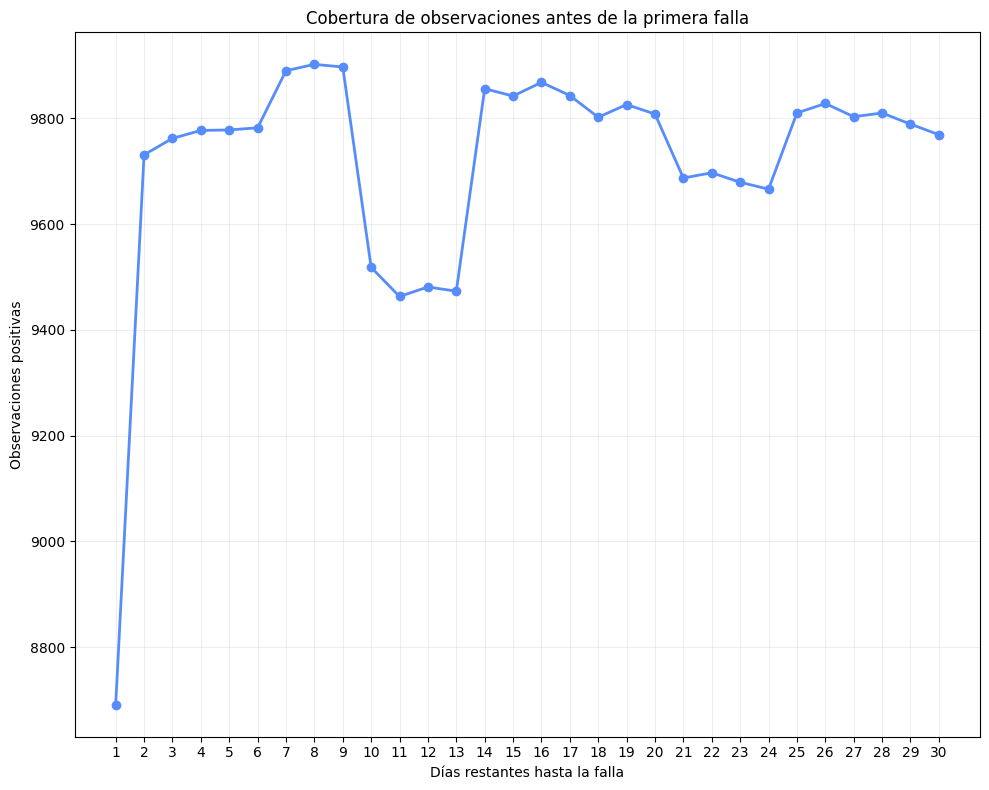

In [38]:
if not positives_by_distance.empty:
    # Ordenar todas las filas según los días restantes hasta la falla.
    ordered = positives_by_distance.sort_values(
        by="DIAS_HASTA_LA_FALLA",
        ascending=False
    )

    figure, axis = plt.subplots(figsize=(10, 8))

    axis.plot(
        ordered["DIAS_HASTA_LA_FALLA"].astype(int),
        ordered["OBSERVACIONES_POSITIVAS"].astype(float),
        marker="o",
        linewidth=2
    )

    axis.set_title("Cobertura de observaciones antes de la primera falla")
    axis.set_xlabel("Días restantes hasta la falla")
    axis.set_ylabel("Observaciones positivas")

    axis.set_xticks(range(1, 31))
    axis.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

### 3.3 Días positivos disponibles por SSD


In [39]:
positive_days_histogram = query_small(f"""
    WITH per_ssd AS (
        SELECT SSD_KEY,
               COUNT(DISTINCT OBSERVATION_DATE) AS POSITIVE_DAYS
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS = 'POSITIVE'
        GROUP BY SSD_KEY
    )
    SELECT POSITIVE_DAYS AS DIAS_POSITIVOS, COUNT(*) AS SSD
    FROM per_ssd
    GROUP BY POSITIVE_DAYS
    ORDER BY DIAS_POSITIVOS
""", max_rows=31)



In [40]:
positive_days_histogram

,DIAS_POSITIVOS,SSD
0,9,12
1,10,17
2,30,5004
3,28,622
4,29,2563
5,22,56
6,23,59
7,16,17
8,17,23
9,18,30


### 3.4 Resumen estadístico de días positivos


In [41]:
positive_days_summary = query_small(f"""
    WITH per_ssd AS (
        SELECT SSD_KEY,
               COUNT(DISTINCT OBSERVATION_DATE) AS POSITIVE_DAYS
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS = 'POSITIVE'
        GROUP BY SSD_KEY
    )
    SELECT COUNT(*) AS SSD_CON_POSITIVOS,
           MIN(POSITIVE_DAYS) AS MINIMO,
           APPROX_PERCENTILE(POSITIVE_DAYS, 0.25) AS CUARTIL_1_APROX,
           APPROX_PERCENTILE(POSITIVE_DAYS, 0.50) AS MEDIANA_APROX,
           AVG(POSITIVE_DAYS::DOUBLE) AS MEDIA,
           APPROX_PERCENTILE(POSITIVE_DAYS, 0.75) AS CUARTIL_3_APROX,
           MAX(POSITIVE_DAYS) AS MAXIMO,
           COALESCE(COUNT_IF(POSITIVE_DAYS >= 7), 0) AS SSD_CON_7_DIAS,
           COALESCE(COUNT_IF(POSITIVE_DAYS >= 14), 0) AS SSD_CON_14_DIAS,
           COALESCE(COUNT_IF(POSITIVE_DAYS >= 21), 0) AS SSD_CON_21_DIAS
    FROM per_ssd
""", max_rows=1)



In [42]:
positive_days_summary

,SSD_CON_POSITIVOS,MINIMO,CUARTIL_1_APROX,MEDIANA_APROX,MEDIA,CUARTIL_3_APROX,MAXIMO,SSD_CON_7_DIAS,SSD_CON_14_DIAS,SSD_CON_21_DIAS
0,10379,1,28.0,29.0,28.088255,30.0,30,10234,10143,10002


### 3.5 Figura 4: historial positivo por SSD


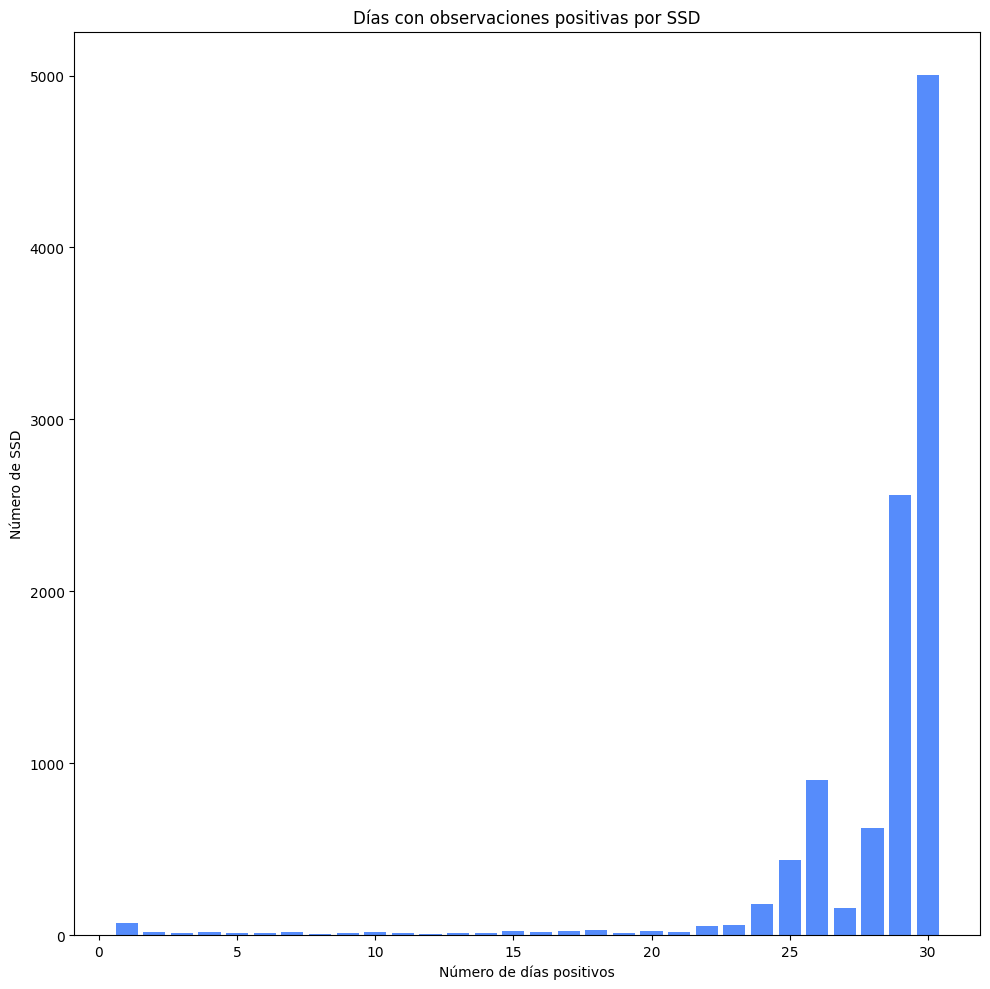

In [43]:
if not positive_days_histogram.empty:
    figure, axis = plt.subplots(figsize=(10, 10))
    axis.bar(positive_days_histogram["DIAS_POSITIVOS"].astype(int),
             positive_days_histogram["SSD"].astype(float))
    axis.set_title("Días con observaciones positivas por SSD")
    axis.set_xlabel("Número de días positivos")
    axis.set_ylabel("Número de SSD")
    plt.tight_layout()
    plt.show()


**Interpretación de la sección 3.** La presencia de registros a varias
distancias confirma cobertura temporal, pero no demuestra por sí sola
que los valores SMART cambien antes de fallar. La completitud de las
trayectorias debe evaluarse por SSD, no solo por el total de filas.


## 4. Comparación inicial entre SMART y la falla


**Control de costo.** En ejecución normal solo se analiza `R_5`.
El resto de las características están separadas por celda y desactivadas
por defecto. Configure `RUN_R5_FEATURES`, `RUN_SELECTED_FAMILY_FIELDS`,
`RUN_IN_DEPTH_ANALYSIS` y `RUN_IQR_ANALYSIS` al inicio de la libreta.
Cada resumen/IQR habilitado puede recorrer millones de observaciones;
revise el costo en Query History antes de aumentar el alcance.


### 4.1 Registro MC1 y selector numérico

El primer menú contiene únicamente mediciones, medias y desplazamientos
presentes en la OBT. Sirve para elegir dos campos en la comparación
SMART–SMART. El segundo menú elige una familia completa (`R` o `N` más
un ID SMART) para compararla con `TARGET_30D`. Los conteos y banderas de
validez quedan fuera de los diagramas de caja e IQR.


In [44]:
menu_rows = []
for prefix in ("R", "N"):
    for smart_id in SMART_IDS:
        root = f"{prefix}_{smart_id}"
        menu_rows.append((root, prefix, smart_id, "valor diario", "—"))
        for window in WINDOWS:
            menu_rows.append((f"{root}_MEAN_{window}D", prefix, smart_id,
                              "media móvil", window))
            menu_rows.append((f"{root}_MEAN_SHIFT_{window}D", prefix, smart_id,
                              "cambio de medias", window))
menu_rows = [row for row in menu_rows if row[0] in FEATURE_NAMES]
feature_menu = pd.DataFrame(
    menu_rows,
    columns=["COLUMNA", "REPRESENTACIÓN", "ATRIBUTO_SMART", "TIPO", "VENTANA_DÍAS"],
)
feature_menu.insert(0, "NÚMERO", range(1, len(feature_menu) + 1))
display(feature_menu)
print("El menú se construye a partir del esquema validado, sin leer filas de la OBT.")

def feature_from_number(number: int) -> str:
    if not isinstance(number, int) or not 1 <= number <= len(feature_menu):
        raise ValueError(f"Seleccione un número entre 1 y {len(feature_menu)}")
    return str(feature_menu.iloc[number - 1]["COLUMNA"])

def ask_feature_number(prompt: str) -> int:
    while True:
        try:
            number = int(input(prompt).strip())
            feature_from_number(number)
            return number
        except ValueError as error:
            print(error)


,NÚMERO,COLUMNA,REPRESENTACIÓN,ATRIBUTO_SMART,TIPO,VENTANA_DÍAS
0,1,R_1,R,1,valor diario,—
1,2,R_1_MEAN_7D,R,1,media móvil,7
2,3,R_1_MEAN_SHIFT_7D,R,1,cambio de medias,7
3,4,R_1_MEAN_14D,R,1,media móvil,14
4,5,R_1_MEAN_SHIFT_14D,R,1,cambio de medias,14
...,...,...,...,...,...,...
303,304,N_211_MEAN_SHIFT_7D,N,211,cambio de medias,7
304,305,N_211_MEAN_14D,N,211,media móvil,14
305,306,N_211_MEAN_SHIFT_14D,N,211,cambio de medias,14
306,307,N_211_MEAN_30D,N,211,media móvil,30


El menú se construye a partir del esquema validado, sin leer filas de la OBT.


### 4.1.1 Menú de familias SMART para comparar con el objetivo


In [45]:
family_menu = pd.DataFrame([
    (prefix, smart_id, f"{prefix}_{smart_id}")
    for prefix in ("R", "N") for smart_id in SMART_IDS
], columns=["REPRESENTACIÓN", "ATRIBUTO_SMART", "FAMILIA"])
family_menu.insert(0, "NÚMERO", range(1, len(family_menu) + 1))
display(family_menu)

def family_from_number(number: int) -> str:
    if not isinstance(number, int) or not 1 <= number <= len(family_menu):
        raise ValueError(f"Seleccione un número entre 1 y {len(family_menu)}")
    return str(family_menu.iloc[number - 1]["FAMILIA"])

def ask_family_number() -> int:
    while True:
        try:
            number = int(input("Número de familia SMART para comparar con la falla: ").strip())
            family_from_number(number)
            return number
        except ValueError as error:
            print(error)


,NÚMERO,REPRESENTACIÓN,ATRIBUTO_SMART,FAMILIA
0,1,R,1,R_1
1,2,R,5,R_5
2,3,R,9,R_9
3,4,R,12,R_12
4,5,R,170,R_170
5,6,R,171,R_171
6,7,R,172,R_172
7,8,R,173,R_173
8,9,R,174,R_174
9,10,R,180,R_180


### 4.2 Funciones compartidas para consultas acotadas


In [46]:
def feature_target_summary(feature: str) -> pd.DataFrame:
    identifier = quote_feature(feature)
    return query_small(f"""
        SELECT YEAR(OBSERVATION_DATE) AS ANIO,
               TARGET_30D AS OBJETIVO,
               COUNT(*) AS OBSERVACIONES_ELEGIBLES,
               COUNT({identifier}) AS OBSERVACIONES_UTILIZABLES,
               COALESCE(COUNT_IF({identifier} IS NULL), 0) AS VALORES_NULOS,
               MIN({identifier}) AS MINIMO,
               APPROX_PERCENTILE({identifier}::DOUBLE, 0.25) AS Q1_APROX,
               AVG({identifier}::DOUBLE) AS MEDIA_APROX,
               APPROX_PERCENTILE({identifier}::DOUBLE, 0.50) AS MEDIANA_APROX,
               APPROX_PERCENTILE({identifier}::DOUBLE, 0.75) AS Q3_APROX,
               MAX({identifier}) AS MAXIMO,
               STDDEV_SAMP({identifier}::DOUBLE) AS DESVIACION_APROX
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
        GROUP BY YEAR(OBSERVATION_DATE), TARGET_30D
        ORDER BY ANIO, OBJETIVO
    """, max_rows=10)


def feature_iqr_summary(feature: str) -> pd.DataFrame:
    identifier = quote_feature(feature)
    return query_small(f"""
        WITH bounds AS (
            SELECT YEAR(OBSERVATION_DATE) AS ANIO,
                   APPROX_PERCENTILE({identifier}::DOUBLE, 0.25) AS Q1,
                   APPROX_PERCENTILE({identifier}::DOUBLE, 0.75) AS Q3
            FROM {OBT_TABLE}
            WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
            GROUP BY YEAR(OBSERVATION_DATE)
        )
        SELECT b.ANIO, b.Q1 AS Q1_APROX, b.Q3 AS Q3_APROX,
               b.Q3 - b.Q1 AS IQR_APROX,
               b.Q1 - 1.5 * (b.Q3 - b.Q1) AS LIMITE_INFERIOR,
               b.Q3 + 1.5 * (b.Q3 - b.Q1) AS LIMITE_SUPERIOR,
               COUNT({identifier}) AS VALORES_UTILIZABLES,
               COALESCE(COUNT_IF({identifier}::DOUBLE < b.Q1 - 1.5 * (b.Q3 - b.Q1)
                        OR {identifier}::DOUBLE > b.Q3 + 1.5 * (b.Q3 - b.Q1)), 0)
                   AS VALORES_EXTREMOS
        FROM {OBT_TABLE} AS s JOIN bounds AS b
          ON YEAR(s.OBSERVATION_DATE) = b.ANIO
        WHERE s.LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
        GROUP BY b.ANIO, b.Q1, b.Q3
        ORDER BY b.ANIO
    """, max_rows=5)


def draw_feature_boxplot(summary: pd.DataFrame, feature: str) -> None:
    if summary.empty:
        print("No hay grupos elegibles para esta característica.")
        return
    boxes = []
    for row in summary.itertuples():
        if int(row.OBSERVACIONES_UTILIZABLES) == 0:
            continue
        boxes.append({
            "label": f"{int(row.ANIO)}: " + (
                "falla en 30 días" if int(row.OBJETIVO) == 1
                else "sin falla registrada"
            ),
            "whislo": float(row.MINIMO),
            "q1": float(row.Q1_APROX),
            "med": float(row.MEDIANA_APROX),
            "q3": float(row.Q3_APROX),
            "whishi": float(row.MAXIMO),
            "fliers": [],
        })
    if not boxes:
        print("No hay valores no nulos para dibujar.")
        return
    figure, axis = plt.subplots(figsize=(9, 3))
    axis.bxp(boxes, vert=False, showfliers=False)
    axis.set_title(f"Distribución aproximada de {feature} según la falla")
    axis.set_xlabel(feature)
    plt.tight_layout()
    plt.show()


print("Medias, desviaciones y cuantiles son aproximados; mínimos y máximos son exactos.")


Medias, desviaciones y cuantiles son aproximados; mínimos y máximos son exactos.


### 4.3 R_5: comparación con el objetivo

Este bloque analiza exclusivamente `R_5` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [47]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5"]:
    r5_summary = feature_target_summary("R_5")
    display(r5_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


,ANIO,OBJETIVO,OBSERVACIONES_ELEGIBLES,OBSERVACIONES_UTILIZABLES,VALORES_NULOS,MINIMO,Q1_APROX,MEDIA_APROX,MEDIANA_APROX,Q3_APROX,MAXIMO,DESVIACION_APROX
0,2018,0,53441973,53435565,6408,0.000000,0.0,6.142187,0.000000,0.000000,11311.000000,117.236968
1,2019,1,234886,234845,41,0.000000,0.0,43.161924,0.000000,1.000000,9071.000000,391.557231
2,2019,0,56358279,56352401,5878,0.000000,0.0,7.905859,0.000000,0.000000,11376.000000,132.355207
3,2018,1,56642,56635,7,0.000000,0.0,85.314152,9.442422,52.732857,8788.000000,396.794587


Población: estados positivo/negativo, resumidos por año.


#### 4.3.1 Figura: distribución de R_5 por objetivo


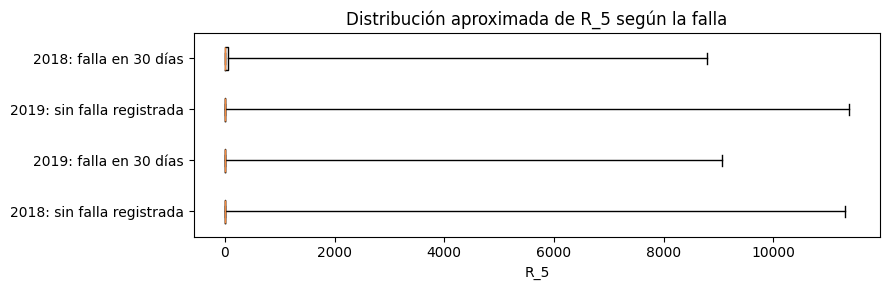

In [48]:
if not r5_summary.empty:
    draw_feature_boxplot(r5_summary, "R_5")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


#### 4.3.2 Valores extremos de R_5 mediante IQR


In [51]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5"]):
    display(feature_iqr_summary("R_5"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


,ANIO,Q1_APROX,Q3_APROX,IQR_APROX,LIMITE_INFERIOR,LIMITE_SUPERIOR,VALORES_UTILIZABLES,VALORES_EXTREMOS
0,2018,0.0,0.0,0.0,0.0,0.0,53492200,7569733
1,2019,0.0,0.0,0.0,0.0,0.0,56587246,11624542


Si IQR = 0, interprete el número de extremos con cautela.
Los valores extremos no se borran: pueden anticipar una falla real.


**Interpretación de `R_5`.** Después de ejecutar el bloque,
compare medianas, cuartiles, tamaños de grupo y valores utilizables.
Una diferencia visual no demuestra causalidad ni capacidad predictiva.


### 4.4 R_5_MEAN_7D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_7D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [52]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_7D"]:
    r5_mean7_summary = feature_target_summary("R_5_MEAN_7D")
    display(r5_mean7_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_mean7_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.4.1 Figura: distribución de R_5_MEAN_7D por objetivo


In [53]:
if not r5_mean7_summary.empty:
    draw_feature_boxplot(r5_mean7_summary, "R_5_MEAN_7D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.4.2 Valores extremos de R_5_MEAN_7D mediante IQR


In [54]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_7D"]):
    display(feature_iqr_summary("R_5_MEAN_7D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.5 R_5_MEAN_14D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_14D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [55]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_14D"]:
    r5_mean14_summary = feature_target_summary("R_5_MEAN_14D")
    display(r5_mean14_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_mean14_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.5.1 Figura: distribución de R_5_MEAN_14D por objetivo


In [56]:
if not r5_mean14_summary.empty:
    draw_feature_boxplot(r5_mean14_summary, "R_5_MEAN_14D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.5.2 Valores extremos de R_5_MEAN_14D mediante IQR


In [57]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_14D"]):
    display(feature_iqr_summary("R_5_MEAN_14D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.6 R_5_MEAN_30D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_30D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [58]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_30D"]:
    r5_mean30_summary = feature_target_summary("R_5_MEAN_30D")
    display(r5_mean30_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_mean30_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.6.1 Figura: distribución de R_5_MEAN_30D por objetivo


In [59]:
if not r5_mean30_summary.empty:
    draw_feature_boxplot(r5_mean30_summary, "R_5_MEAN_30D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.6.2 Valores extremos de R_5_MEAN_30D mediante IQR


In [60]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_30D"]):
    display(feature_iqr_summary("R_5_MEAN_30D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.7 R_5_MEAN_SHIFT_7D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_SHIFT_7D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [61]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_7D"]:
    r5_shift7_summary = feature_target_summary("R_5_MEAN_SHIFT_7D")
    display(r5_shift7_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_shift7_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.7.1 Figura: distribución de R_5_MEAN_SHIFT_7D por objetivo


In [62]:
if not r5_shift7_summary.empty:
    draw_feature_boxplot(r5_shift7_summary, "R_5_MEAN_SHIFT_7D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.7.2 Valores extremos de R_5_MEAN_SHIFT_7D mediante IQR


In [63]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_7D"]):
    display(feature_iqr_summary("R_5_MEAN_SHIFT_7D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.8 R_5_MEAN_SHIFT_14D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_SHIFT_14D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [64]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_14D"]:
    r5_shift14_summary = feature_target_summary("R_5_MEAN_SHIFT_14D")
    display(r5_shift14_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_shift14_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.8.1 Figura: distribución de R_5_MEAN_SHIFT_14D por objetivo


In [65]:
if not r5_shift14_summary.empty:
    draw_feature_boxplot(r5_shift14_summary, "R_5_MEAN_SHIFT_14D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.8.2 Valores extremos de R_5_MEAN_SHIFT_14D mediante IQR


In [66]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_14D"]):
    display(feature_iqr_summary("R_5_MEAN_SHIFT_14D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.9 R_5_MEAN_SHIFT_30D: comparación con el objetivo

Este bloque analiza exclusivamente `R_5_MEAN_SHIFT_30D` entre observaciones
`POSITIVE` y `NEGATIVE`. El recuento elegible y el recuento no nulo
se presentan por separado; no se eliminan datos de la OBT.
Se ejecuta solamente si se activa su entrada en `RUN_R5_FEATURES`
o si `RUN_IN_DEPTH_ANALYSIS=True`. Su IQR necesita además `RUN_IQR_ANALYSIS=True`.


In [67]:
if RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_30D"]:
    r5_shift30_summary = feature_target_summary("R_5_MEAN_SHIFT_30D")
    display(r5_shift30_summary)
    print("Población: estados positivo/negativo, resumidos por año.")
else:
    r5_shift30_summary = pd.DataFrame()
    print("Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.")


Análisis desactivado: habilite RUN_R5_FEATURES o RUN_IN_DEPTH_ANALYSIS.


#### 4.9.1 Figura: distribución de R_5_MEAN_SHIFT_30D por objetivo


In [68]:
if not r5_shift30_summary.empty:
    draw_feature_boxplot(r5_shift30_summary, "R_5_MEAN_SHIFT_30D")
else:
    print("Figura omitida: el análisis de esta característica está desactivado.")


Figura omitida: el análisis de esta característica está desactivado.


#### 4.9.2 Valores extremos de R_5_MEAN_SHIFT_30D mediante IQR


In [69]:
if RUN_IQR_ANALYSIS and (RUN_IN_DEPTH_ANALYSIS or RUN_R5_FEATURES["R_5_MEAN_SHIFT_30D"]):
    display(feature_iqr_summary("R_5_MEAN_SHIFT_30D"))
    print("Si IQR = 0, interprete el número de extremos con cautela.")
    print("Los valores extremos no se borran: pueden anticipar una falla real.")
else:
    print("IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.")


IQR omitido: active RUN_IQR_ANALYSIS y la característica elegida.


### 4.10 Familia SMART alternativa elegida con el menú

Active `RUN_SELECTED_FAMILY` en la configuración e introduzca el número
del menú de **familias**. Por defecto se ejecuta solo su valor diario;
active entradas individuales en `RUN_SELECTED_FAMILY_FIELDS` para las
medias/cambios adicionales, o use `RUN_IN_DEPTH_ANALYSIS` para todos.
Los IQR de esa familia requieren además `RUN_IQR_ANALYSIS=True`.
Cada campo tiene su propia tabla, figura e IQR.


In [70]:
default_family_number = int(
    family_menu.loc[family_menu["FAMILIA"] == "R_5", "NÚMERO"].iloc[0]
)
SELECTED_FAMILY_NUMBER = (
    ask_family_number() if RUN_SELECTED_FAMILY else default_family_number
)
selected_family = family_from_number(SELECTED_FAMILY_NUMBER)

def selected_family_feature(suffix: str) -> str:
    if suffix not in ("", "_MEAN_7D", "_MEAN_14D", "_MEAN_30D",
                      "_MEAN_SHIFT_7D", "_MEAN_SHIFT_14D", "_MEAN_SHIFT_30D"):
        raise ValueError("Sufijo SMART no admitido")
    feature = selected_family + suffix
    if feature not in FEATURE_NAMES:
        raise ValueError(f"La OBT no contiene {feature}")
    return feature

print("Familia elegida:", selected_family)
print("RUN_SELECTED_FAMILY ejecuta el campo diario; active otros campos por separado.")


Familia elegida: R_5
RUN_SELECTED_FAMILY ejecuta el campo diario; active otros campos por separado.


### 4.10.1 Familia elegida: valor diario


In [71]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS[""]):
    family_current_summary_feature = selected_family_feature("")
    family_current_summary = feature_target_summary(family_current_summary_feature)
    display(family_current_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.1.1 Figura: valor diario


In [72]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS[""]):
    draw_feature_boxplot(family_current_summary, family_current_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.1.2 Valores extremos: valor diario


In [73]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS[""]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_current_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


**Interpretación.** Examine por separado `valor diario`: compare las clases y los años, observe la cobertura no nula y no atribuya causalidad a una diferencia descriptiva.


### 4.10.2 Familia elegida: media de 7 días


In [74]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_7D"]):
    family_mean7_summary_feature = selected_family_feature("_MEAN_7D")
    family_mean7_summary = feature_target_summary(family_mean7_summary_feature)
    display(family_mean7_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.2.1 Figura: media de 7 días


In [75]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_7D"]):
    draw_feature_boxplot(family_mean7_summary, family_mean7_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.2.2 Valores extremos: media de 7 días


In [76]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_7D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_mean7_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.10.3 Familia elegida: media de 14 días


In [77]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_14D"]):
    family_mean14_summary_feature = selected_family_feature("_MEAN_14D")
    family_mean14_summary = feature_target_summary(family_mean14_summary_feature)
    display(family_mean14_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.3.1 Figura: media de 14 días


In [79]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_14D"]):
    draw_feature_boxplot(family_mean14_summary, family_mean14_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.3.2 Valores extremos: media de 14 días


In [80]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_14D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_mean14_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.10.4 Familia elegida: media de 30 días


In [81]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_30D"]):
    family_mean30_summary_feature = selected_family_feature("_MEAN_30D")
    family_mean30_summary = feature_target_summary(family_mean30_summary_feature)
    display(family_mean30_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.4.1 Figura: media de 30 días


In [82]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_30D"]):
    draw_feature_boxplot(family_mean30_summary, family_mean30_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.4.2 Valores extremos: media de 30 días


In [83]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_30D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_mean30_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.10.5 Familia elegida: cambio de media de 7 días


In [84]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_7D"]):
    family_shift7_summary_feature = selected_family_feature("_MEAN_SHIFT_7D")
    family_shift7_summary = feature_target_summary(family_shift7_summary_feature)
    display(family_shift7_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.5.1 Figura: cambio de media de 7 días


In [85]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_7D"]):
    draw_feature_boxplot(family_shift7_summary, family_shift7_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.5.2 Valores extremos: cambio de media de 7 días


In [86]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_7D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_shift7_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.10.6 Familia elegida: cambio de media de 14 días


In [87]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_14D"]):
    family_shift14_summary_feature = selected_family_feature("_MEAN_SHIFT_14D")
    family_shift14_summary = feature_target_summary(family_shift14_summary_feature)
    display(family_shift14_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.6.1 Figura: cambio de media de 14 días


In [88]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_14D"]):
    draw_feature_boxplot(family_shift14_summary, family_shift14_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.6.2 Valores extremos: cambio de media de 14 días


In [89]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_14D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_shift14_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.10.7 Familia elegida: cambio de media de 30 días


In [90]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_30D"]):
    family_shift30_summary_feature = selected_family_feature("_MEAN_SHIFT_30D")
    family_shift30_summary = feature_target_summary(family_shift30_summary_feature)
    display(family_shift30_summary)
    print("Año y objetivo se mantienen separados en la tabla.")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.7.1 Figura: cambio de media de 30 días


In [91]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_30D"]):
    draw_feature_boxplot(family_shift30_summary, family_shift30_summary_feature)
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


#### 4.10.7.2 Valores extremos: cambio de media de 30 días


In [92]:
if RUN_SELECTED_FAMILY and (RUN_IN_DEPTH_ANALYSIS or RUN_SELECTED_FAMILY_FIELDS["_MEAN_SHIFT_30D"]):
    if RUN_IQR_ANALYSIS:
        display(feature_iqr_summary(family_shift30_summary_feature))
    else:
        print("IQR optativo desactivado (RUN_IQR_ANALYSIS=False).")
else:
    print("Bloque de familia optativo sin ejecutar.")


Bloque de familia optativo sin ejecutar.


### 4.11 Comparación optativa de dos características SMART

Elija **dos números diferentes** del menú anterior. Los resultados
cuantifican asociación lineal entre mediciones observadas en la misma
fila; no evalúan causalidad ni sustituyen la comparación con el objetivo.
Active `RUN_PAIR_ANALYSIS` para ejecutar los bloques de consulta y figura.


In [93]:
default_a_number = int(
    feature_menu.loc[feature_menu["COLUMNA"] == "R_5", "NÚMERO"].iloc[0]
)
default_b_number = int(
    feature_menu.loc[feature_menu["COLUMNA"] == "R_5_MEAN_7D", "NÚMERO"].iloc[0]
)
FEATURE_A_NUMBER = (
    ask_feature_number("Número de la primera característica SMART: ")
    if RUN_PAIR_ANALYSIS else default_a_number
)
FEATURE_B_NUMBER = (
    ask_feature_number("Número de la segunda característica SMART: ")
    if RUN_PAIR_ANALYSIS else default_b_number
)
feature_a = feature_from_number(FEATURE_A_NUMBER)
feature_b = feature_from_number(FEATURE_B_NUMBER)
while feature_a == feature_b and RUN_PAIR_ANALYSIS:
    print("Seleccione dos características distintas.")
    FEATURE_B_NUMBER = ask_feature_number("Otro número para la segunda característica: ")
    feature_b = feature_from_number(FEATURE_B_NUMBER)
print("Pareja elegida:", feature_a, "y", feature_b)


Pareja elegida: R_5 y R_5_MEAN_7D


#### 4.11.1 Tabla de covarianza y correlación


In [94]:
if RUN_PAIR_ANALYSIS:
    a = quote_feature(feature_a)
    b = quote_feature(feature_b)
    pair_summary = query_small(f"""
        SELECT COALESCE(COUNT_IF({a} IS NOT NULL AND {b} IS NOT NULL), 0)
                   AS PARES_UTILIZABLES,
               COVAR_SAMP({a}::DOUBLE, {b}::DOUBLE) AS COVARIANZA,
               CORR({a}::DOUBLE, {b}::DOUBLE) AS CORRELACION,
               REGR_SLOPE({b}::DOUBLE, {a}::DOUBLE) AS PENDIENTE_B_SOBRE_A
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
    """, max_rows=1)
    display(pair_summary)
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


#### 4.11.2 Figura acotada de la pareja elegida


In [95]:
if RUN_PAIR_ANALYSIS:
    pair_sample = query_small(f"""
        SELECT {a} AS CARACTERISTICA_A, {b} AS CARACTERISTICA_B
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS IN ('POSITIVE', 'NEGATIVE')
              AND {a} IS NOT NULL AND {b} IS NOT NULL
              AND MOD(HASH(SMART_DAILY_KEY), 1000) = 0
        ORDER BY HASH(SMART_DAILY_KEY), SMART_DAILY_KEY
        LIMIT 1000
    """, max_rows=1000)
    if not pair_sample.empty:
        figure, axis = plt.subplots(figsize=(7, 5))
        axis.scatter(pair_sample["CARACTERISTICA_A"].astype(float),
                     pair_sample["CARACTERISTICA_B"].astype(float),
                     alpha=0.25, s=8)
        axis.set_title(f"Relación exploratoria entre {feature_a} y {feature_b}")
        axis.set_xlabel(feature_a)
        axis.set_ylabel(feature_b)
        plt.tight_layout()
        plt.show()
    else:
        print("La muestra reproducible no devolvió pares observados.")
    print("Figura: submuestra estable por hash (~0,1 %), máximo 1000 filas.")
    print("La tabla anterior usa toda la población elegible; la figura no.")
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


### 4.12 Trayectoria optativa de un SSD antes de la falla


In [96]:
if RUN_TRAJECTORY:
    trajectory_candidate = query_small(f"""
        SELECT SSD_KEY, COUNT(DISTINCT OBSERVATION_DATE) AS DIAS_POSITIVOS
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS = 'POSITIVE'
        GROUP BY SSD_KEY
        ORDER BY DIAS_POSITIVOS DESC, SSD_KEY
        LIMIT 1
    """, max_rows=1)
    display(trajectory_candidate)
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


#### 4.12.1 Puntos diarios acotados del SSD elegido


In [97]:
if RUN_TRAJECTORY and not trajectory_candidate.empty:
    ssd_key = str(trajectory_candidate.iloc[0]["SSD_KEY"])
    ssd_key_literal = "'" + ssd_key.replace("'", "''") + "'"
    trajectory = query_small(f"""
        SELECT OBSERVATION_DATE, FIRST_FAILURE_DATE,
               R_5, R_5_MEAN_7D, R_5_MEAN_SHIFT_7D
        FROM {OBT_TABLE}
        WHERE SSD_KEY = {ssd_key_literal}
              AND FIRST_FAILURE_DATE IS NOT NULL
              AND OBSERVATION_DATE BETWEEN
                  DATEADD('day', -30, FIRST_FAILURE_DATE) AND FIRST_FAILURE_DATE
        ORDER BY OBSERVATION_DATE, SMART_DAILY_KEY
        LIMIT 35
    """, max_rows=35)
    display(trajectory)
elif RUN_TRAJECTORY:
    print("No hay un SSD con falla confirmada para esta trayectoria.")
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


#### 4.12.2 Figura de la trayectoria de un SSD


In [98]:
if RUN_TRAJECTORY and not trajectory_candidate.empty and not trajectory.empty:
    figure, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
    for axis, feature in zip(axes, ("R_5", "R_5_MEAN_7D", "R_5_MEAN_SHIFT_7D")):
        axis.plot(pd.to_datetime(trajectory["OBSERVATION_DATE"]),
                  trajectory[feature].astype(float), marker="o")
        axis.axvline(pd.to_datetime(trajectory["FIRST_FAILURE_DATE"].iloc[0]),
                     color="red", linestyle="--", label="Primera falla")
        axis.set_ylabel(feature)
        axis.legend()
    axes[0].set_title("Trayectoria ilustrativa de un SSD antes de la falla")
    axes[-1].set_xlabel("Fecha de observación")
    plt.tight_layout()
    plt.show()
elif RUN_TRAJECTORY:
    print("No hay puntos de trayectoria para representar.")
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


### 4.13 Trayectoria agregada optativa por días restantes


In [99]:
if RUN_AGGREGATE_TRAJECTORY:
    aggregate_trajectory = query_small(f"""
        SELECT DAYS_TO_FAILURE AS DIAS_HASTA_LA_FALLA,
               APPROX_PERCENTILE(R_5::DOUBLE, 0.50) AS MEDIANA_R5_APROX,
               COUNT(DISTINCT SSD_KEY) AS SSD_DISTINTOS
        FROM {OBT_TABLE}
        WHERE LABEL_STATUS = 'POSITIVE' AND DAYS_TO_FAILURE BETWEEN 1 AND 30
        GROUP BY DAYS_TO_FAILURE
        ORDER BY DIAS_HASTA_LA_FALLA DESC
    """, max_rows=30)
    display(aggregate_trajectory)
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


#### 4.13.1 Figura de la trayectoria agregada


In [100]:
if RUN_AGGREGATE_TRAJECTORY and not aggregate_trajectory.empty:
    figure, first_axis = plt.subplots(figsize=(10, 4))
    second_axis = first_axis.twinx()
    x = aggregate_trajectory["DIAS_HASTA_LA_FALLA"].astype(int)
    first_axis.plot(x, aggregate_trajectory["MEDIANA_R5_APROX"].astype(float),
                    marker="o", color="tab:blue")
    second_axis.bar(x, aggregate_trajectory["SSD_DISTINTOS"].astype(float),
                    alpha=0.2, color="tab:orange")
    first_axis.invert_xaxis()
    first_axis.set_title("Mediana aproximada de R_5 antes de la falla")
    first_axis.set_xlabel("Días restantes hasta la falla")
    first_axis.set_ylabel("Mediana aproximada de R_5")
    second_axis.set_ylabel("SSD contribuyentes")
    plt.tight_layout()
    plt.show()
elif RUN_AGGREGATE_TRAJECTORY:
    print("No hay observaciones positivas para representar.")
else:
    print("Bloque optativo sin ejecutar.")


Bloque optativo sin ejecutar.


## 5. Tres hallazgos y consecuencias para el modelado


Complete estos hallazgos **después de ejecutar** las consultas. No
convierta los ejemplos en conclusiones predeterminadas. Cada hallazgo
debe citar una tabla o figura y el período analizado.

### Hallazgo 1: equilibrio de clases

- **Observación:** completar con la tasa positiva y la razón de clases.
- **Evidencia:** tabla 2.3 y figura 1 o 2.
- **Interpretación:** distinguir observaciones de SSD y eventos de falla.
- **Consecuencia:** definir métricas adecuadas; no aplicar remuestreo aquí.

### Hallazgo 2: cobertura temporal

- **Observación:** completar con días positivos por SSD y distancias cubiertas.
- **Evidencia:** tablas 3.1, 3.3, 3.4 y figuras 3–4.
- **Interpretación:** indicar si hay trayectorias completas o fragmentadas.
- **Consecuencia:** decidir qué ventanas temporales merecen evaluación.

### Hallazgo 3: característica y calidad de la etiqueta

- **Observación:** completar según un bloque SMART y la cobertura anual.
- **Evidencia:** tabla/figura de sección 4 y tabla 2.4.
- **Interpretación:** considerar sesgo, valores extremos y cobertura de etiquetas en ambos años.
- **Consecuencia:** proponer un experimento posterior sin afirmar causalidad.
